# SleePyLand scoring for several files: EOG1 + EOG2, averaged (v2)

> This file is intended to be run inside the sleepyland architecture.
> To run, clone the [repo](https://github.com/biomedical-signal-processing/sleepyland), [download and run](https://hub.docker.com/r/bspsupsi/sleepyland) sleepyland, and insert this file into the my-notebook folder.
> Put the original EDFs in the folder `raw_edf` and the manually scored EDF(s) in the folder `manual_scored`, **both next to this notebook** (i.e. inside `my-notebook/`, not in `../input`: the sleepyland GUI empties `/app/input` on every run).

**What is new compared with `scoring_multifile` / `scoring_multifile_EOG2`**
* **All files are scored twice**: first with EOG1, then with EOG2 (section 7). The two runs are **averaged per night** (and per model), and the average is used for everything that follows (sections 8b, 9, 10). The average of the two runs is *not* an EOG1+EOG2 ensemble (nothing is re-scored): it is the mean of the two per-night values (accuracy, kappa, sleep statistics, ...).
* **Section 8b**: the per-night accuracies of every model are tested for **normal distribution** (Shapiro-Wilk + Q-Q plot).
* **Section 10**: non-inferiority is tested **twice**, with the one-sided **t-test** and the one-sided **Wilcoxon signed-rank test**, and the two are compared side by side.
* **Nothing from earlier runs is overwritten.** Everything is written to the new folder `OUT_ROOT = sleepyland_results_v2` (`EOG1/`, `EOG2/` for the single runs, `average/` for the report) and sleepyland's own output folders get new names (`out_<name>_v2_EOG1`, `out_<name>_v2_EOG2`).

What this file does:
1. set configurations
2. preprocess data (de-saturate samples --> band-pass filter --> resample to 128Hz --> clip outliers --> export); preprocessing statistics are recorded per file
3. prepare for sleepyland
4. load manual scoring
5. define YASA, statistics (hypnogram & metrics) and plot functions
6. define scoring function
7. score all EDFs of the folder with all available models, **once with EOG1, once with EOG2**, then average the two runs per night
8. (optional) look at results of every single file; always: per-night accuracy of both runs and the average
8b. test the per-night accuracies for normal distribution
9. report across files: averages of all metrics (on the averaged nights) and of the preprocessing statistics; saved to `report_across_files.xlsx`
10. non-inferiority tests: t-test, Wilcoxon signed-rank test and their comparison

## 1. set configurations

In [2]:
#%pip install openpyxl
#%pip install edfio

import os
os.environ["MNE_USE_NUMBA"] = "false"   #set before mne is imported

import re, glob, shutil, traceback, mne
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import requests, edfio
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

# -------------------- CONFIGURE ME --------------------
# --- Folders (sleepyland's predict_one reads only from API_DIR = /app/input/myedf)
RAW_DIR    = Path("raw_edf")            # ORIGINAL EDF files: folder next to this notebook (my-notebook/raw_edf), not searched recursively
API_DIR    = Path("../input/myedf")     # = /app/input/myedf in the container. Must contain only the file being scored.
MANUAL_DIR = Path("manual_scored")      # optional: manually scored EDF(+) files, folder next to this notebook (annotations are enough)
AUTO_MOVE_ORIGINALS = True              # EDFs found in API_DIR are moved to RAW_DIR (never deleted)
RENAME_MANUAL = True                    # rename every manual scoring in MANUAL_DIR from xx.edf to xx_scored.edf (once, at the start of section 7)

EPOCH_SEC     = 30                      # epoch length in seconds
EXPORT_SET    = False                   # also export EEGLAB .set (needs: pip install eeglabio)
FORCE_RESCORE = True                    # True = ignore the "already scored" skip rule (skipped files are NOT part of the report in section 9)
SHOW_PER_FILE = False                   # section 8: True = show tables and plots for every single file (long), False = only the report in section 9

# Channels, first match wins (case-insensitive).
EEG_CANDIDATES = ["FpZ", "EEG"]
EOG_RUNS = ["EOG1", "EOG2"]   # every file is scored once per EOG channel (in this order); the runs are then averaged per night
EOG_CANDIDATES = [EOG_RUNS[0]]   # set automatically for every run in section 7 (single channel, no fallback: a file is never silently scored with another EOG)
EMG_CANDIDATES = ["EMG1", "EMG2", "EMG"]   # only used for the optional native YASA run

# --- Signal preparation for sleepyland
BANDPASS        = (0.3, 35.0)    # Hz, zero-phase FIR. None = off (NOT recommended for this device: huge DC drift)
RESAMPLE_HZ     = 128            # sleepyland resamples to 128 Hz internally anyway
DESATURATE      = True           # linearly interpolate samples at the ADC limit before filtering (avoids filter ringing)
SATURATION_UV   = 180_000.0      # device range is +-187.5 mV
CLIP_IQR_FACTOR = 20.0           # clip at +-20*IQR after filtering (sleepyland uses the same rule)
EEG_LABEL       = "C4"           # renaming the channel: Container-YASA skips non-central EEG (FpZ!). Deep models only look at the type "EEG".
EOG_LABEL       = "EOG"
KEEP_PREPARED   = True           # keep the prepared EDF in OUT_ROOT/<EOG>/prepared for inspection

# --- Scoring
MODELS        = ["usleep", "deepresnet", "transformer", "yasa", "ensemble"]
PRIMARY_MODEL = "ensemble"          # its hypnogram is written into the scored EDF as annotations
RUN_YASA_NATIVE = True            # extra reference: YASA run directly in this notebook (needs `import yasa`), on the ORIGINAL signal

# --- Manual scoring (optional). Explicit mapping wins: {"<raw edf file name>": "<path to scored edf>"}
MANUAL_SCORING    = {}
MIN_COMMON_PREFIX = 45            # fallback if there is no exact xx.edf <-> xx_scored.edf match: scored EDF whose name shares >= this many leading characters with the raw EDF

# --- Sleepyland paths / API (normally no change needed inside the container)
API_URL      = "http://manager-api:8989"
OUTPUT_ROOTS = [Path("../output"), Path("/app/output")]   # where sleepyland writes <output_name>/<model>/majority/*.npy
OUT_ROOT = Path("sleepyland_results_v2")   # NEW folder for everything this notebook writes. Never one of the folders of earlier runs.
OUT_DIR  = OUT_ROOT                        # set automatically: OUT_ROOT/EOG1 and OUT_ROOT/EOG2 while scoring, OUT_ROOT/average for the report
OUT_TAG  = "_sleepyland"                   # set automatically per run: _sleepyland_EOG1 / _sleepyland_EOG2
CURRENT_EOG = EOG_RUNS[0]                  # set automatically per run
RUN_TAG = f"v2_{CURRENT_EOG}"              # set automatically; part of the name of sleepyland's output folder (out_<name>_v2_EOG1 ...)
# ------------------------------------------------------

PREVIOUS_FOLDERS = {"sleepyland_results", "sleepyland_results_EOG2", "sleepyland_results_EOG1_EOG2"}   # results of the earlier notebooks
assert OUT_ROOT.name not in PREVIOUS_FOLDERS, f"OUT_ROOT = {OUT_ROOT}: this is a folder of an earlier run and would be overwritten. Choose a new name."

STAGE_NAMES  = ["Wake", "N1", "N2", "N3", "REM"]        # model output order (argmax index)
STAGE_LABELS = ["W", "N1", "N2", "N3", "R"]             # annotation labels
STAGE_COLORS = ["#58e306", "#2cf7f0", "#1173ef", "#4b4d4d", "#ee0e0e"]

mkdir -p failed for path /home/jovyan/.cache/matplotlib: [Errno 13] Permission denied: '/home/jovyan/.cache/matplotlib'
Matplotlib created a temporary cache directory at /tmp/matplotlib-lr2c_z37 because there was an issue with the default path (/home/jovyan/.cache/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


## 2. preprocess data
--> Helper functions: channels, folders, signal preparation

In [3]:
def find_channel(ch_names, candidates):
    """First channel matching any candidate (case-insensitive, trailing '.' ignored), else None."""
    lookup = {c.lower().rstrip("."): c for c in ch_names}
    for cand in candidates:
        hit = lookup.get(cand.lower().rstrip("."))
        if hit is not None:
            return hit
    return None


def base_name(path):
    return re.sub(r"(_scored)+$", "", Path(path).stem)


def list_edfs(folder):
    """All *.edf files directly in folder (case-insensitive, sorted, not recursive)."""
    folder = Path(folder)
    if not folder.exists():
        return []
    return sorted(p for p in folder.iterdir() if p.is_file() and p.suffix.lower() == ".edf")


def rename_manual_files():
    """Rename every manual scoring in MANUAL_DIR from xx.edf to xx_scored.edf (files already ending in _scored are left alone)."""
    if not MANUAL_DIR.exists():
        print(f"(manual folder {MANUAL_DIR} does not exist - no manual scorings)")
        return
    if MANUAL_DIR.resolve() == RAW_DIR.resolve():
        raise RuntimeError("MANUAL_DIR and RAW_DIR are the same folder: renaming would rename your recordings. "
                           "Please use two different folders.")
    n = 0
    for f in list_edfs(MANUAL_DIR):
        if f.stem.endswith("_scored"):
            continue
        target = f.with_name(f"{f.stem}_scored{f.suffix}")
        if target.exists():
            print(f"⚠️ not renamed: {target.name} already exists (kept {f.name})")
            continue
        f.rename(target)
        n += 1
        print(f"  ✏️ renamed manual scoring {f.name} -> {target.name}")
    print(f"manual scorings: {len(list_edfs(MANUAL_DIR))} file(s) in {MANUAL_DIR} ({n} renamed)")


def is_scored_or_manual_file(path):
    """Never treat '*_scored.edf' (manual scoring / earlier output) as a recording."""
    return str(path).endswith("_scored.edf")


def already_scored(raw_path):
    scored = OUT_DIR / f"{base_name(raw_path)}{OUT_TAG}_scored.edf"
    return scored.exists() and scored.stat().st_mtime >= Path(raw_path).stat().st_mtime


def ensure_folders():
    """Originals must NOT stay in API_DIR: predict_one scores every EDF it finds there."""
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    API_DIR.mkdir(parents=True, exist_ok=True)
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    for f in list_edfs(API_DIR):
        target = RAW_DIR / f.name
        if not AUTO_MOVE_ORIGINALS:
            raise RuntimeError(f"{f} is in {API_DIR}. Move it to {RAW_DIR} (or set AUTO_MOVE_ORIGINALS=True).")
        if target.exists():
            raise RuntimeError(f"{f} is in {API_DIR}, but {target} already exists. Please clean up by hand.")
        shutil.move(str(f), str(target))
        print(f"  ↪ moved {f.name} from {API_DIR} to {RAW_DIR}")


def channel_stats(raw):
    """Amplitude statistics per channel in µV."""
    rows = []
    for ch, x in zip(raw.ch_names, raw.get_data(units="uV")):
        rows.append({"channel": ch, "median_uV": np.median(x), "std_uV": x.std(),
                     "IQR_uV": np.subtract(*np.percentile(x, [75, 25])),
                     "max_abs_uV": np.abs(x).max()})
    return pd.DataFrame(rows).set_index("channel").round(1)


def _runs(mask, sfreq):
    """Lengths (s) of the consecutive True stretches of a boolean mask."""
    d = np.diff(np.r_[0, mask.astype(int), 0])
    return (np.flatnonzero(d == -1) - np.flatnonzero(d == 1)) / sfreq


def _iqr(x):
    return float(np.subtract(*np.percentile(x, [75, 25])))


def prepare_for_sleepyland(raw, eeg, eog):
    """Pick EEG (+EOG), de-saturate, band-pass, resample, clip artefacts, rename to EEG_LABEL / EOG_LABEL.

    Returns (prepared raw, DataFrame with the preprocessing statistics, one row per channel).

    No rescaling: sleepyland applies its own RobustScaler (median 0, IQR 1) and it only works if the
    IQR reflects the EEG and not the DC drift.
    """
    r = raw.copy().pick([eeg] + ([eog] if eog else []))
    rename = {eeg: EEG_LABEL}
    if eog:
        rename[eog] = EOG_LABEL
    r.rename_channels({k: v for k, v in rename.items() if k != v})
    pst = {ch: {} for ch in r.ch_names}           # preprocessing statistics per channel
    sf0 = r.info["sfreq"]

    for ch in r.ch_names:                          # raw amplitude + saturation statistics
        x = r.get_data(picks=ch, units="uV")[0]
        pst[ch].update(raw_median_uV=float(np.median(x)), raw_IQR_uV=_iqr(x))
        sat = np.abs(x) >= SATURATION_UV
        seg = _runs(sat, sf0)
        pst[ch].update(n_sat_samples=int(sat.sum()), pct_saturated=100 * float(sat.mean()),
                       n_sat_segments=int(seg.size), longest_sat_s=float(seg.max()) if seg.size else 0.0,
                       total_sat_s=float(seg.sum()), n_interpolated_samples=0)
        if DESATURATE and sat.any() and not sat.all():   # samples at the ADC limit: linear interpolation
            idx = np.arange(x.size)
            x[sat] = np.interp(idx[sat], idx[~sat], x[~sat])
            r.apply_function(lambda a, x=x: x * 1e-6, picks=[ch])   # data is in volts
            pst[ch]["n_interpolated_samples"] = int(sat.sum())
            print(f"    {ch}: {100 * sat.mean():.3f} % saturated samples interpolated "
                  f"({seg.size} stretch(es), longest {seg.max():.1f} s)")

    if BANDPASS is not None:
        l_freq, h_freq = BANDPASS
        nyq = r.info["sfreq"] / 2
        if h_freq and h_freq >= nyq:
            print(f"    high cut-off {h_freq} Hz >= Nyquist ({nyq:g} Hz): high-pass only")
            h_freq = None
        r.filter(l_freq=l_freq, h_freq=h_freq, picks="all", method="fir", phase="zero", verbose=False)
        print(f"    band-pass {l_freq}-{h_freq if h_freq else 'none'} Hz applied")

    if RESAMPLE_HZ and r.info["sfreq"] != RESAMPLE_HZ:
        r.resample(RESAMPLE_HZ, npad="auto")

    L = int(round(r.info["sfreq"] * EPOCH_SEC))
    for ch in r.ch_names:   # clip artefacts -> small physical range in the exported EDF
        x = r.get_data(picks=ch, units="uV")[0]
        iqr = _iqr(x)
        pst[ch].update(IQR_after_filter_uV=iqr)
        if iqr == 0:
            print(f"    {ch}: IQR = 0 (flat channel?), not clipped")
            continue
        lim = CLIP_IQR_FACTOR * iqr
        clipped = np.abs(x) > lim                  # exactly the samples np.clip changes below
        n_ep = x.size // L
        rms = np.sqrt((np.clip(x, -lim, lim)[:n_ep * L].reshape(n_ep, L) ** 2).mean(1))
        pst[ch].update(clip_limit_uV=lim, pct_samples_clipped=100 * float(clipped.mean()),
                       pct_epochs_with_clipping=100 * float(clipped[:n_ep * L].reshape(n_ep, L).any(1).mean()),
                       pct_epochs_flat=100 * float((rms < 2).mean()),            # epoch RMS < 2 uV
                       pct_epochs_artefact=100 * float((rms > 150).mean()))      # epoch RMS > 150 uV
        print(f"    {ch}: IQR = {iqr:.1f} µV -> clip at ±{lim:.0f} µV ({100 * clipped.mean():.2f} % of samples, "
              f"{pst[ch]['pct_epochs_with_clipping']:.1f} % of epochs contain clipped samples)")
        r.apply_function(lambda a, l=lim * 1e-6: np.clip(a, -l, l), picks=[ch])
    return r, pd.DataFrame(pst).T.rename_axis("channel")


def verify_prepared(path):
    """Read the exported EDF back and warn if it still looks wrong."""
    chk = mne.io.read_raw_edf(str(path), preload=True, verbose=False)
    stats = channel_stats(chk)
    print("  prepared EDF as sleepyland will read it:"); display(stats)
    for ch, row in stats.iterrows():
        if abs(row["median_uV"]) > 5 * max(row["IQR_uV"], 1e-9):
            print(f"  ⚠️ {ch}: median ({row['median_uV']:.0f} µV) >> IQR – DC offset left? Check BANDPASS.")
        if row["IQR_uV"] < 3 or row["IQR_uV"] > 300:
            print(f"  ⚠️ {ch}: IQR = {row['IQR_uV']:.1f} µV is unusual for sleep EEG/EOG.")

## 3. prepare for sleepyland
--> Helper functions: sleepyland API and prediction files

In [4]:
def api_post(endpoint, data=None, params=None):
    """POST to the manager API; raises with the server's message on failure."""
    r = requests.post(f"{API_URL}/{endpoint}", data=data, params=params)
    if r.status_code != 200:
        raise RuntimeError(f"{endpoint} failed ({r.status_code}): {r.text}")
    return r.json()


def run_prediction(prep_edf, output_name, models, channels):
    """Put exactly ONE prepared EDF into API_DIR (the only folder predict_one reads), run predict_one, clean up."""
    leftovers = list(API_DIR.glob("*.edf"))
    if leftovers:
        raise RuntimeError(f"{API_DIR} must be empty before scoring, found: {[f.name for f in leftovers]}")
    for root in OUTPUT_ROOTS:                       # no stale predictions from earlier runs
        shutil.rmtree(root / output_name, ignore_errors=True)
    target = API_DIR / Path(prep_edf).name
    shutil.copy(prep_edf, target)
    try:
        return api_post("predict_one", data={
            "folder_root_name": API_DIR.name,       # ignored by the API (hard-coded /app/input/myedf), kept for the signature
            "folder_name": output_name,
            "channels": list(channels),
            "models": list(models),
            "resolution": str(EPOCH_SEC),
        })
    finally:
        target.unlink(missing_ok=True)


def list_output(output_name):
    """Print every file sleepyland wrote for this output folder (use it if results are not found)."""
    for root in OUTPUT_ROOTS:
        d = root / output_name
        if d.exists():
            print(f"{d}:")
            for p in sorted(d.rglob("*")):
                if p.is_file():
                    print("  ", p.relative_to(d))
            return
    print(f"No output folder '{output_name}' in {[str(r) for r in OUTPUT_ROOTS]}")


def find_prediction(output_name, model):
    """The .npy prediction of a model (majority vote preferred)."""
    for root in OUTPUT_ROOTS:
        base = root / output_name / model
        if base.exists():
            files = sorted((base / "majority").glob("*.npy")) or sorted(base.rglob("*.npy"))
            files = [f for f in files if "TRUE" not in f.name]
            if files:
                return files[0]
    return None


def load_prediction(path):
    """(stages as int array, probabilities [n_epochs x 5] or None)"""
    arr = np.squeeze(np.load(path))
    if arr.ndim == 2:
        return arr.argmax(-1).astype(int), arr
    return arr.astype(int), None


def load_results(output_name, models):
    res = {}
    for m in models:
        p = find_prediction(output_name, m)
        if p is None:
            print(f"    no prediction found for {m}")
        else:
            res[m] = load_prediction(p)
    return res


def run_yasa_native(raw, eeg, eog, emg, n_epochs):
    """YASA directly on the original signal (does its own 0.4-30 Hz filtering)."""
    import yasa
    picks = [c for c in (eeg, eog, emg) if c]
    r = raw.copy().pick(picks)
    r.resample(100, npad="auto")
    sls = yasa.SleepStaging(r, eeg_name=eeg, eog_name=eog, emg_name=emg)
    y = sls.predict()
    if hasattr(y, "as_int"):                                  # yasa >= 0.7: Hypnogram object
        st = np.asarray(y.as_int()).astype(int)
    else:                                                     # yasa <= 0.6: array of 'W','N1',...
        st = pd.Series(np.asarray(y)).map({"W": 0, "N1": 1, "N2": 2, "N3": 3, "R": 4}).to_numpy().astype(int)
    st[(st < 0) | (st > 4)] = 0
    return st[:n_epochs], None

## 4. load manual scorings
Reads stage annotations from the scored EDF and converts them to 30 s epochs. Everything that is not a sleep stage (arousals, …) is ignored. Epochs without a stage get `-1` and are excluded from the metrics.

In [5]:
_STAGE_MAP = {"w": 0, "wake": 0, "1": 1, "n1": 1, "2": 2, "n2": 2, "3": 3, "n3": 3, "4": 3, "n4": 3, "r": 4, "rem": 4}


def _stage_from_desc(desc):
    d = desc.strip().lower().replace("sleep stage", "").replace("stage", "").strip()
    return _STAGE_MAP.get(d)


def manual_hypnogram(scored_edf, n_epochs, epoch_sec=EPOCH_SEC):
    """int array [n_epochs] with 0..4, -1 = not scored. Onsets are relative to the recording start."""
    ann = mne.read_annotations(str(scored_edf))
    h = np.full(n_epochs, -1, dtype=int)
    for onset, dur, desc in zip(ann.onset, ann.duration, ann.description):
        s = _stage_from_desc(desc)
        if s is None:
            continue
        a, b = int(round(onset / epoch_sec)), int(round((onset + dur) / epoch_sec))
        h[max(a, 0):min(b, n_epochs)] = s
    return h


def find_manual_edf(raw_path):
    """Manual scoring for a recording: explicit mapping > xx_scored.edf for xx.edf > longest common name prefix."""
    explicit = MANUAL_SCORING.get(Path(raw_path).name)
    if explicit:
        return Path(explicit)
    cands = list_edfs(MANUAL_DIR)
    if not cands:
        return None
    base = base_name(raw_path)
    for p in cands:                                   # exact: xx.edf <-> xx_scored.edf
        if base_name(p) == base:
            return p
    best, best_len = None, 0                          # fallback: longest common prefix of the names
    for p in cands:
        n = len(os.path.commonprefix([base_name(p), base]))
        if n > best_len:
            best, best_len = p, n
    return best if best_len >= MIN_COMMON_PREFIX else None


def evaluate_against_manual(results, manual):
    """Per-model accuracy, kappa, macro-F1, per-stage F1 and confusion matrices vs. the manual hypnogram."""
    from sklearn.metrics import cohen_kappa_score, accuracy_score, f1_score, confusion_matrix
    rows, cms = [], {}
    for m, (st, _) in results.items():
        n = min(len(st), len(manual))
        y, p = manual[:n], np.asarray(st[:n])
        ok = y >= 0
        if ok.sum() == 0:
            continue
        f1 = f1_score(y[ok], p[ok], labels=range(5), average=None, zero_division=0)
        rows.append({"model": m, "n_epochs": int(ok.sum()),
                     "accuracy": accuracy_score(y[ok], p[ok]), "kappa": cohen_kappa_score(y[ok], p[ok]),
                     "macro_F1": f1.mean(), **{f"F1_{s}": v for s, v in zip(STAGE_LABELS, f1)},
                     "%Wake_pred": 100 * (p[ok] == 0).mean()})
        cms[m] = confusion_matrix(y[ok], p[ok], labels=range(5))
    table = pd.DataFrame(rows).set_index("model").round(3) if rows else None
    return table, cms


def confusion_df(cm):
    """Row-normalised (% of manual epochs), rows = manual, columns = prediction."""
    with np.errstate(invalid="ignore", divide="ignore"):
        pct = 100 * cm / cm.sum(1, keepdims=True)
    return pd.DataFrame(np.nan_to_num(pct), index=[f"manual {s}" for s in STAGE_LABELS],
                        columns=[f"pred {s}" for s in STAGE_LABELS]).round(1)

## 5. define YASA_native, statistics (hypnogram & metrics) and plot functions

In [6]:
def _first_run(is_sleep, min_len):
    run = 0
    for i, v in enumerate(is_sleep):
        run = run + 1 if v else 0
        if run >= min_len:
            return i - min_len + 1
    return None


def sleep_statistics(stages, epoch_sec=EPOCH_SEC):
    """YASA's sleep statistics (all durations in minutes), computed from an int hypnogram 0..4.

    Lat_REM is measured from the start of the recording (YASA convention);
    Lat_REM_from_SOL is the AASM definition (from first sleep epoch).
    """
    st = np.asarray(stages)
    epm = 60 / epoch_sec                         # epochs per minute
    is_sleep = st > 0
    idx = np.flatnonzero(is_sleep)
    s = {"TIB": len(st) / epm}
    if idx.size == 0:
        s.update({k: np.nan for k in ["SPT", "WASO", "TST", "SE", "SME", "SFI", "SOL", "SOL_5min"]})
        s["TST"] = 0.0
    else:
        first, last = idx[0], idx[-1]
        s["SPT"] = (last + 1 - first) / epm
        s["WASO"] = np.sum(st[first:last + 1] == 0) / epm
        s["TST"] = is_sleep[first:last + 1].sum() / epm
        s["SE"] = 100 * s["TST"] / s["TIB"]
        s["SME"] = 100 * s["TST"] / s["SPT"]
        s["SFI"] = np.count_nonzero(is_sleep[:-1] & (st[1:] == 0)) / (s["TST"] / 60)
        s["SOL"] = first / epm
        r5 = _first_run(is_sleep, int(np.ceil(5 * epm - 1e-9)))
        s["SOL_5min"] = r5 / epm if r5 is not None else np.nan
    rem = np.flatnonzero(st == 4)
    s["Lat_REM"] = rem[0] / epm if rem.size else np.nan
    s["Lat_REM_from_SOL"] = s["Lat_REM"] - s["SOL"] if rem.size and idx.size else np.nan
    for j, name in enumerate(["WAKE", "N1", "N2", "N3", "REM"]):
        s[name] = np.sum(st == j) / epm
    for name in ["N1", "N2", "N3", "REM"]:
        s[f"%{name}"] = 100 * s[name] / s["TST"] if s["TST"] > 0 else np.nan
    return {k: round(float(v), 4) for k, v in s.items()}


def with_manual(results, manual):
    """results + the manual hypnogram as first entry (unscored epochs counted as Wake for the statistics/plots only)."""
    if manual is None:
        return dict(results)
    return {"manual": (np.where(manual < 0, 0, manual), None), **results}


def summary_table(results):
    return pd.DataFrame({m: sleep_statistics(st) for m, (st, _) in results.items()}).T


def model_agreement(results):
    from sklearn.metrics import cohen_kappa_score
    rows = []
    for a, b in combinations(results, 2):
        sa, sb = results[a][0], results[b][0]
        n = min(len(sa), len(sb))
        rows.append({"pair": f"{a} vs {b}",
                     "agreement_%": 100 * (sa[:n] == sb[:n]).mean(),
                     "kappa": cohen_kappa_score(sa[:n], sb[:n])})
    return pd.DataFrame(rows).set_index("pair").round(2) if rows else None


_YPOS = {0: 4, 4: 3, 1: 2, 2: 1, 3: 0}                  # Wake on top, then REM, N1, N2, N3
_YTICKS = dict(tickvals=[0, 1, 2, 3, 4], ticktext=["N3", "N2", "N1", "REM", "Wake"])


def _ypos(st):
    return [_YPOS.get(int(s), np.nan) for s in st]


def plot_hypnograms(results, title):
    """Interactive plotly hypnograms, one row per model (and the manual scoring, if available)."""
    n = len(results)
    fig = make_subplots(rows=n, cols=1, shared_xaxes=True, vertical_spacing=0.06,
                        subplot_titles=list(results))
    for i, (model, (st, _)) in enumerate(results.items(), start=1):
        t = np.arange(len(st)) * EPOCH_SEC / 3600
        fig.add_trace(go.Scatter(
            x=t, y=_ypos(st), mode="lines+markers",
            line=dict(color="#bdc2c3", width=1.5, shape="hv"),
            marker=dict(size=4, color=[STAGE_COLORS[int(s)] for s in st]),
            customdata=[STAGE_NAMES[int(s)] for s in st],
            hovertemplate="%{x:.2f} h  %{customdata}<extra></extra>",
            showlegend=False), row=i, col=1)
        fig.update_yaxes(range=[-0.5, 4.5], **_YTICKS, row=i, col=1)
    fig.update_xaxes(title_text="Time (h)", row=n, col=1)
    fig.update_layout(title=f"Hypnograms: {title}", height=240 * n + 100)
    fig.show()


def plot_hypnodensity(results, title):
    for model, (_, probs) in results.items():
        if probs is None:
            print(f"{model}: no probabilities available, skipping hypnodensity")
            continue
        t = np.arange(len(probs)) * EPOCH_SEC / 3600
        fig = go.Figure()
        for j, name in enumerate(STAGE_NAMES):
            fig.add_trace(go.Scatter(x=t, y=probs[:, j], name=name, mode="lines", stackgroup="one",
                                     line=dict(width=0.5, color=STAGE_COLORS[j])))
        fig.update_layout(title=f"Hypnodensity: {model} ({title})", xaxis_title="Time (h)",
                          yaxis_title="Probability", yaxis_range=[0, 1], height=350)
        fig.show()


def save_hypnogram_png(results, path, title):
    """Static PNG (like YASA notebook), one panel per model."""
    fig, axes = plt.subplots(len(results), 1, figsize=(12, 2.8 * len(results)),
                             sharex=True, squeeze=False)
    for ax, (model, (st, _)) in zip(axes[:, 0], results.items()):
        ax.step(np.arange(len(st)) * EPOCH_SEC / 3600, _ypos(st), where="post", lw=1)
        ax.set_yticks([0, 1, 2, 3, 4])
        ax.set_yticklabels(["N3", "N2", "N1", "REM", "W"])
        ax.set_title(model, loc="left", fontsize=10)
        ax.grid(alpha=0.3)
    axes[-1, 0].set_xlabel("Time (h)")
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(path, dpi=200)
    plt.close(fig)

## 6. define scoring function
`score_edf_sleepyland(edf_path)` returns `{"results": {model: (stages, probs)}, "manual": hypnogram or None, "eval": table or None, "manual_file": name or None, "prep": preprocessing statistics per channel}`.  
Outputs are written to `OUT_DIR`: `<base>_sleepyland_scored.edf` (original, unprocessed data of all channels + hypnogram of `PRIMARY_MODEL` as annotations), `_hypnogram.csv`, `_hypnogram.png`, `_metrics.xlsx` (one sheet per model, plus `vs_manual`), optionally `.set`, and the prepared EDF in `OUT_DIR/prepared`.

In [7]:
def score_edf_sleepyland(edf_path):
    edf_path = str(edf_path)
    if not FORCE_RESCORE and already_scored(edf_path):
        print(f"⏭️  Skipping (already scored & up-to-date): {os.path.basename(edf_path)}")
        return None
    print(f"🔄 Processing: {os.path.basename(edf_path)}")

    # ---- load + channel selection
    raw = mne.io.read_raw_edf(edf_path, preload=True, verbose=False)
    eeg = find_channel(raw.ch_names, EEG_CANDIDATES)
    eog = find_channel(raw.ch_names, EOG_CANDIDATES)
    emg = find_channel(raw.ch_names, EMG_CANDIDATES)
    if eeg is None:
        raise ValueError(f"No EEG channel {EEG_CANDIDATES} found. Available: {raw.ch_names}")
    print(f"→ EEG: {eeg} | EOG: {eog} | EMG: {emg} (EMG only for native YASA)"
          f" | {raw.info['sfreq']:g} Hz | {raw.n_times / raw.info['sfreq'] / 3600:.2f} h")
    if eog is None:
        print("  ⚠️ no EOG channel found, scoring with EEG only")
    n_full = int(raw.n_times / raw.info["sfreq"] // EPOCH_SEC)

    # ---- prepare the sleepyland input
    base = base_name(edf_path)
    safe = re.sub(r"[^A-Za-z0-9]+", "_", base).strip("_")
    output_name = f"out_{safe}_{RUN_TAG}"          # new name per run: earlier predictions in the output volume stay untouched

    print("  before:"); display(channel_stats(raw.copy().pick([c for c in [eeg, eog] if c])))
    prep, prep_stats = prepare_for_sleepyland(raw, eeg, eog)
    prep_stats["duration_h"] = raw.n_times / raw.info["sfreq"] / 3600
    prep_stats["n_epochs"] = n_full
    prep_dir = OUT_DIR / "prepared"
    prep_dir.mkdir(parents=True, exist_ok=True)
    prep_edf = prep_dir / f"{safe}.edf"
    mne.export.export_raw(str(prep_edf), prep, fmt="edf", overwrite=True)
    verify_prepared(prep_edf)

    # ---- score with sleepyland (file is copied into API_DIR only for the duration of the call)
    channels = ["EEG"] + (["EOG"] if eog else [])
    print(f"  scoring with {MODELS} ...")
    run_prediction(prep_edf, output_name, MODELS, channels)
    if not KEEP_PREPARED:
        prep_edf.unlink(missing_ok=True)

    results = load_results(output_name, MODELS)
    if "yasa" not in results and "yasa" in MODELS:
        print("  ℹ️ no YASA result: the container only runs YASA on central EEG labels (C1..C6, Cz). "
              f"Prepared label is '{EEG_LABEL}'. Check: docker compose logs usleepyland | grep -i skipping")
    if RUN_YASA_NATIVE:
        try:
            results["yasa_native"] = run_yasa_native(raw, eeg, eog, emg, n_full)
        except Exception as e:
            print(f"  ⚠️ native YASA failed: {e}")
    if not results:
        list_output(output_name)
        raise RuntimeError("Sleepyland ran, but no prediction files were found (see listing above). "
                           "Look at the container log: docker compose logs usleepyland manager-api")

    for m, (st, _) in results.items():
        if abs(len(st) - n_full) > 1:
            print(f"  ⚠️ {m}: {len(st)} epochs predicted, recording has {n_full} full epochs")

    # ---- manual scoring
    manual, eval_table = None, None
    manual_edf = find_manual_edf(edf_path)
    if manual_edf is not None:
        manual = manual_hypnogram(manual_edf, n_full)
        print(f"  manual scoring: {manual_edf.name} ({(manual >= 0).sum()} of {n_full} epochs scored)")
        eval_table, cms = evaluate_against_manual(results, manual)
    else:
        print("  (no manual scoring found – put the scored EDF into MANUAL_DIR for a quantitative comparison)")

    # ---- outputs (same set as the YASA notebook)
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    edf_out = OUT_DIR / f"{base}{OUT_TAG}_scored.edf"
    csv_out = OUT_DIR / f"{base}{OUT_TAG}_hypnogram.csv"
    png_out = OUT_DIR / f"{base}{OUT_TAG}_hypnogram.png"
    xls_out = OUT_DIR / f"{base}{OUT_TAG}_metrics.xlsx"
    set_out = OUT_DIR / f"{base}{OUT_TAG}_scored.set"

    primary = PRIMARY_MODEL if PRIMARY_MODEL in results else next(iter(results))
    if primary != PRIMARY_MODEL:
        print(f"  ⚠️ {PRIMARY_MODEL} has no result, using {primary} for the annotations")
    st_primary = results[primary][0][:n_full]
    raw.set_annotations(mne.Annotations(               # replaces existing annotations, as in the YASA code
        onset=np.arange(len(st_primary)) * EPOCH_SEC,
        duration=[EPOCH_SEC] * len(st_primary),
        description=[STAGE_LABELS[s] for s in st_primary]))
    try:
        raw.export(str(edf_out), fmt="edf", overwrite=True)    # original, unprocessed data of all channels
    except Exception as e:
        print(f"  ⚠️ scored EDF export failed ({e}); the other outputs are still written")

    all_rows = with_manual(results, manual)
    n_max = max(len(st) for st, _ in all_rows.values())
    table = pd.DataFrame({"Time (h)": np.arange(n_max) * EPOCH_SEC / 3600})
    for m, (st, _) in all_rows.items():
        table[m] = pd.Series([STAGE_LABELS[s] for s in st])
    if manual is not None:
        table["manual"] = pd.Series([STAGE_LABELS[s] if s >= 0 else "" for s in manual])
    table.to_csv(csv_out, index=False)

    save_hypnogram_png(all_rows, png_out, f"Hypnogram – {base} ({CURRENT_EOG})")

    stats = {m: sleep_statistics(st) for m, (st, _) in all_rows.items()}
    try:
        with pd.ExcelWriter(xls_out) as xw:
            for m, s in stats.items():
                pd.DataFrame(s, index=[0]).to_excel(xw, sheet_name=m[:31], index=False)
            if eval_table is not None:
                eval_table.to_excel(xw, sheet_name="vs_manual")
    except Exception as e:                                   # e.g. openpyxl missing
        print(f"  ⚠️ Excel export failed ({e}), writing CSV instead")
        pd.DataFrame(stats).T.to_csv(xls_out.with_suffix(".csv"))
        if eval_table is not None:
            eval_table.to_csv(xls_out.with_name(xls_out.stem + "_vs_manual.csv"))

    if EXPORT_SET:
        try:
            mne.export.export_raw(str(set_out), raw, fmt="eeglab", overwrite=True)
            print(f"  💾 Exported EEGLAB .set: {set_out}")
        except Exception as e:
            print(f"  ⚠️ EEGLAB .set export failed: {e}")

    print(f"✅ Done: {edf_out.name}\n")
    return {"results": results, "manual": manual, "eval": eval_table,
            "manual_file": manual_edf.name if manual_edf is not None else None, "prep": prep_stats}

## 7. score all EDFs of the folder with all available models: EOG1 and EOG2 in two separate cells, then average
Two ways to run this section (the result is identical):
* **7a** prepares everything, **7b** scores all files with EOG1, **7c** scores all files with EOG2. Each of the two run cells can be started on its own (also in another session or on another day).
* Every night is saved per run in `OUT_ROOT/EOG1` or `OUT_ROOT/EOG2` in the same format: `*_hypnogram.csv/png`, `*_metrics.xlsx`, `*_scored.edf` **and** `*_run.pkl` (all results of the night: predictions, probabilities, manual scoring, evaluation, preprocessing statistics).
* The average (next section) takes the runs from memory, or - if the kernel was restarted or only one run was done in this session - **loads the missing run from the `*_run.pkl` files on disk**. So EOG1 and EOG2 do not need to be scored in the same session.

sleepyland's `predict_one` always reads one fixed folder, `/app/input/myedf`, so only one prepared file can be in it at a time: the files are scored one after the other.

In [8]:
#check if writable
import os, stat, subprocess
print("uid/gid:", os.getuid(), os.getgid())
for p in [API_DIR.parent, API_DIR]:
    s = p.stat()
    print(p.resolve(), oct(stat.S_IMODE(s.st_mode)), "owner uid", s.st_uid,
          "| writable:", os.access(p, os.W_OK))
print(subprocess.run(["ls", "-la", str(API_DIR)], capture_output=True, text=True).stdout)

uid/gid: 1000 100
/app/input 0o777 owner uid 0 | writable: True
/app/input/myedf 0o777 owner uid 1000 | writable: True
total 15260
drwxrwxrwx 1 jovyan users     4096 Nov  6 14:25 .
drwxrwxrwx 1 root   root      4096 Nov  3 10:30 ..
-rw-r--r-- 1 jovyan users 15623440 Nov  6 14:25 11_E2_7B_2A_A0_71_Axo_Device_071_20250421_204304_000019.edf



In [9]:
# if myedf is not writable > recreate it (old one is kept as myedf_old). Safe to run again.
if not API_DIR.exists():
    API_DIR.mkdir(parents=True); os.chmod(API_DIR, 0o777)
    print(f"created {API_DIR}")
elif os.access(API_DIR, os.W_OK):
    print(f"{API_DIR} is writable - nothing to do")
else:
    old = API_DIR.with_name("myedf_old")
    if old.exists():
        raise RuntimeError(f"{old} already exists, please clean up by hand (docker compose exec -u root ... chmod -R a+rwX {API_DIR.resolve()})")
    os.rename(API_DIR, old)
    API_DIR.mkdir(); os.chmod(API_DIR, 0o777)
    print(f"{API_DIR} was not writable: recreated it, the old folder is now {old}")

../input/myedf is writable - nothing to do


In [10]:
# 7a. setup (run once per session) + the function that scores all files with ONE EOG channel
import pickle

OUT_DIR = OUT_ROOT
ensure_folders()
if RENAME_MANUAL:
    rename_manual_files()
try:
    r = requests.get(f"{API_URL}/docs", timeout=5)
    print(f"manager-api reachable (HTTP {r.status_code})")
except Exception as e:
    print(f"⚠️ manager-api not reachable at {API_URL}: {e}")

edf_files = [str(f) for f in list_edfs(RAW_DIR) if not is_scored_or_manual_file(f)]
print(f"Found {len(edf_files)} EDF file(s) in {RAW_DIR.resolve()}")

results_by_eog, failed_by_eog = {}, {}      # filled by the run cells 7b / 7c (or loaded from disk in the averaging cell)


def _run_pkl(eog, name):
    safe = re.sub(r"[^A-Za-z0-9]+", "_", name).strip("_")
    return OUT_ROOT / eog / f"{safe}_sleepyland_{eog}_run.pkl"


def run_eog(eog):
    """Score all files with the EOG channel `eog` and save every night in OUT_ROOT/<eog> (same format for every channel)."""
    global CURRENT_EOG, EOG_CANDIDATES, RUN_TAG, OUT_DIR, OUT_TAG
    assert eog in EOG_RUNS, f"{eog} is not in EOG_RUNS = {EOG_RUNS}"
    # settings of this run (read by the functions of section 2-6 at call time)
    CURRENT_EOG, EOG_CANDIDATES, RUN_TAG = eog, [eog], f"v2_{eog}"
    OUT_DIR, OUT_TAG = OUT_ROOT / eog, f"_sleepyland_{eog}"
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    print("#" * 78 + f"\n# RUN WITH {eog}   (results: {OUT_DIR})\n" + "#" * 78)

    all_results, failed = {}, {}
    for i, f in enumerate(edf_files, 1):
        print(f"\n[{eog}  {i}/{len(edf_files)}] " + "-" * 56)
        name = base_name(f)
        try:
            res = score_edf_sleepyland(f)
            if res:
                with open(_run_pkl(eog, name), "wb") as fh:
                    pickle.dump({"name": name, "eog": eog, "out": res}, fh)
            elif _run_pkl(eog, name).exists():            # skipped (FORCE_RESCORE = False): take the saved result
                with open(_run_pkl(eog, name), "rb") as fh:
                    res = pickle.load(fh)["out"]
                print(f"  ↩️ loaded the saved result of {name} ({eog})")
            if res:
                all_results[name] = res
        except Exception as e:
            failed[f] = e
            print(f"❌ {os.path.basename(f)} failed ({eog}): {e}\n")
            traceback.print_exc(limit=2)
    results_by_eog[eog], failed_by_eog[eog] = all_results, failed

    used = {}                                         # a manual scoring must belong to exactly one recording
    for n, o in all_results.items():
        if o["manual_file"]:
            used.setdefault(o["manual_file"], []).append(n)
    for mf, names in used.items():
        if len(names) > 1:
            print(f"⚠️ manual scoring {mf} was matched to several recordings: {names} - check names / MANUAL_SCORING")
    print(f"\n{eog} done. Scored: {len(all_results)} | failed: {len(failed)} | saved in {OUT_DIR.resolve()}")
    OUT_DIR = OUT_ROOT


def load_run_from_disk(eog):
    """Results of a run that were saved by run_eog (only for the files that are in RAW_DIR now)."""
    wanted = {base_name(f) for f in edf_files}
    out = {}
    for p in sorted((OUT_ROOT / eog).glob("*_run.pkl")):
        with open(p, "rb") as fh:
            d = pickle.load(fh)
        if d["name"] in wanted:
            out[d["name"]] = d["out"]
    return out


  ↪ moved 11_E2_7B_2A_A0_71_Axo_Device_071_20250421_204304_000019.edf from ../input/myedf to raw_edf
manual scorings: 46 file(s) in manual_scored (0 renamed)
manager-api reachable (HTTP 200)
Found 24 EDF file(s) in /app/my-notebook/raw_edf


In [ ]:
# 7b. score all files with EOG1
run_eog("EOG1")


##############################################################################
# RUN WITH EOG1   (results: sleepyland_results_v2/EOG1)
##############################################################################

[EOG1  1/24] --------------------------------------------------------
🔄 Processing: 04-49-15-4B-D3-6E_Axo-Device-075_20250707_204037_000009.edf
→ EEG: FpZ | EOG: EOG1 | EMG: EMG1 (EMG only for native YASA) | 250 Hz | 8.53 h
  before:


,median_uV,std_uV,IQR_uV,max_abs_uV
channel,,,,
FpZ,21672.6,25841.2,46532.4,187500.0
EOG1,8237.0,19723.3,30218.6,187500.0


    C4: 0.432 % saturated samples interpolated (6 stretch(es), longest 108.5 s)
    EOG: 0.066 % saturated samples interpolated (5 stretch(es), longest 10.6 s)
    band-pass 0.3-35.0 Hz applied
    C4: IQR = 23.4 µV -> clip at ±469 µV (1.01 % of samples, 12.0 % of epochs contain clipped samples)
    EOG: IQR = 23.9 µV -> clip at ±478 µV (0.76 % of samples, 13.9 % of epochs contain clipped samples)
Overwriting existing file.
  prepared EDF as sleepyland will read it:


,median_uV,std_uV,IQR_uV,max_abs_uV
channel,,,,
C4,-0.5,65.6,23.4,468.5
EOG,-0.2,65.9,23.9,478.5


  scoring with ['usleep', 'deepresnet', 'transformer', 'yasa', 'ensemble'] ...


/opt/conda/lib/python3.12/site-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator LabelEncoder from version 0.24.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


... (125 outputs left out)

,median_uV,std_uV,IQR_uV,max_abs_uV
channel,,,,
FpZ,2720.9,7391.0,1195.9,187500.0
EOG1,3144.3,8845.6,1539.3,187500.0


    C4: 0.110 % saturated samples interpolated (4 stretch(es), longest 9.6 s)
    EOG: 0.201 % saturated samples interpolated (3 stretch(es), longest 12.5 s)
    band-pass 0.3-35.0 Hz applied
    C4: IQR = 20.2 µV -> clip at ±403 µV (0.34 % of samples, 4.7 % of epochs contain clipped samples)
    EOG: IQR = 25.3 µV -> clip at ±506 µV (0.32 % of samples, 4.5 % of epochs contain clipped samples)
Overwriting existing file.
  prepared EDF as sleepyland will read it:


,median_uV,std_uV,IQR_uV,max_abs_uV
channel,,,,
C4,0.0,37.2,20.2,403.3
EOG,-0.1,47.5,25.3,506.4


  scoring with ['usleep', 'deepresnet', 'transformer', 'yasa', 'ensemble'] ...


In [9]:
# 7c. score all files with EOG2
run_eog("EOG2")


##############################################################################
# RUN WITH EOG2   (results: sleepyland_results_v2/EOG2)
##############################################################################

[EOG2  1/23] --------------------------------------------------------
🔄 Processing: 04-49-15-4B-D3-6E_Axo-Device-075_20250707_204037_000009.edf
→ EEG: FpZ | EOG: EOG2 | EMG: EMG1 (EMG only for native YASA) | 250 Hz | 8.53 h
  before:


,median_uV,std_uV,IQR_uV,max_abs_uV
channel,,,,
FpZ,21672.6,25841.2,46532.4,187500.0
EOG2,6829.4,21118.9,26968.4,187500.0


    C4: 0.432 % saturated samples interpolated (6 stretch(es), longest 108.5 s)
    EOG: 0.552 % saturated samples interpolated (4 stretch(es), longest 126.2 s)
    band-pass 0.3-35.0 Hz applied
    C4: IQR = 23.4 µV -> clip at ±469 µV (1.01 % of samples, 12.0 % of epochs contain clipped samples)
    EOG: IQR = 18.3 µV -> clip at ±367 µV (0.87 % of samples, 12.0 % of epochs contain clipped samples)
Overwriting existing file.
  prepared EDF as sleepyland will read it:


,median_uV,std_uV,IQR_uV,max_abs_uV
channel,,,,
C4,-0.5,65.6,23.4,468.5
EOG,0.6,50.4,18.3,366.9


  scoring with ['usleep', 'deepresnet', 'transformer', 'yasa', 'ensemble'] ...


/opt/conda/lib/python3.12/site-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator LabelEncoder from version 0.24.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


... (125 outputs left out)

,median_uV,std_uV,IQR_uV,max_abs_uV
channel,,,,
C4,0.0,37.2,20.2,403.3
EOG,0.3,35.6,17.7,354.8


  scoring with ['usleep', 'deepresnet', 'transformer', 'yasa', 'ensemble'] ...


/opt/conda/lib/python3.12/site-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator LabelEncoder from version 0.24.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


  manual scoring: 33-54-23-13-A2-FD_Axo-Device-072_20250529_003439_000018_RvL_scored.edf (552 of 552 epochs scored)
✅ Done: 33-54-23-13-A2-FD_Axo-Device-072_20250529_003439_000018_sleepyland_EOG2_scored.edf


EOG2 done. Scored: 22 | failed: 1 | saved in /app/my-notebook/sleepyland_results_v2/EOG2


### average of the runs
Per night, the values of the two runs are averaged: `(EOG1 + EOG2) / 2` for accuracy, kappa, F1, % Wake, the sleep statistics, the model agreement, the preprocessing statistics and the (row-normalised) confusion matrices. A night / model is only included if it has a result in **all** runs; anything else is dropped with a message, so that the average never silently rests on one run. NaN values (e.g. a latency that does not exist in one run) are ignored in the mean.
`RUN_TABLES` = per-night tables of each run, `AVG_TABLES` = the averaged tables that sections 8b, 9 and 10 use.
If a run was not done in this session, its nights are loaded from the `*_run.pkl` files in `OUT_ROOT/<EOG>`.

In [12]:
import warnings

KEYS = {"prep": ["file", "channel"], "eval": ["file", "model"], "stats": ["file", "model"], "agree": ["file", "pair"]}


def collect_night_tables(all_results):
    """Long tables of one run (one row per night x channel/model/pair) and the per-night confusion matrices (% of manual epochs)."""
    prep, ev, st, agr, cms = [], [], [], [], {}
    for name, out in all_results.items():
        res, manual, e = out["results"], out["manual"], out["eval"]
        if out.get("prep") is not None:
            prep.append(out["prep"].reset_index().assign(file=name))
        st.append(summary_table(with_manual(res, manual)).rename_axis("model").reset_index().assign(file=name))
        a = model_agreement(res)
        if a is not None:
            agr.append(a.reset_index().assign(file=name))
        if e is not None:
            ev.append(e.reset_index().assign(file=name))
            _, cm_dict = evaluate_against_manual(res, manual)
            for m, cm in cm_dict.items():
                with np.errstate(invalid="ignore", divide="ignore"):      # NaN row if a stage is absent in the manual scoring
                    cms.setdefault(m, {})[name] = 100 * cm / cm.sum(1, keepdims=True)
    cat = lambda L: pd.concat(L, ignore_index=True) if L else None
    return {"prep": cat(prep), "eval": cat(ev), "stats": cat(st), "agree": cat(agr), "cms": cms}


for e in EOG_RUNS:                                    # a run that was not done in this session: load it from disk
    if not results_by_eog.get(e):
        results_by_eog[e] = load_run_from_disk(e)
        failed_by_eog.setdefault(e, {})
        if results_by_eog[e]:
            print(f"ℹ️ run {e}: {len(results_by_eog[e])} night(s) loaded from {OUT_ROOT / e}")
missing_runs = [e for e in EOG_RUNS if not results_by_eog.get(e)]
if missing_runs:
    raise RuntimeError(f"No result in run(s) {missing_runs}: nothing to average. Run the cell(s) 7b / 7c for these channels first.")
RUN_TABLES = {eog: collect_night_tables(res) for eog, res in results_by_eog.items()}

NIGHTS = sorted(set.intersection(*[set(results_by_eog[e]) for e in EOG_RUNS]))
for e in EOG_RUNS:
    extra = sorted(set(results_by_eog[e]) - set(NIGHTS))
    if extra:
        print(f"⚠️ only in run {e} (not in all runs, left out of the average): {extra}")
print(f"{len(NIGHTS)} night(s) in all runs: {NIGHTS}")


def average_long(kind):
    """Per-night average of the runs for table `kind` (rows missing in a run are dropped)."""
    parts = []
    for eog in EOG_RUNS:
        t = RUN_TABLES[eog][kind]
        if t is None:
            print(f"  ⚠️ table '{kind}' is missing in run {eog}: not averaged")
            return None
        parts.append(t.assign(run=eog))
    allp = pd.concat(parts, ignore_index=True)
    allp = allp[allp["file"].isin(NIGHTS)]
    keys = KEYS[kind]
    counts = allp.groupby(keys, sort=False)["run"].nunique()
    dropped = counts[counts < len(EOG_RUNS)]
    if len(dropped):
        print(f"  ⚠️ {kind}: {len(dropped)} row(s) exist in only some runs and are dropped, e.g. {list(dropped.index[:4])}")
    allp = allp.set_index(keys)
    allp = allp[allp.index.isin(counts[counts == len(EOG_RUNS)].index)]
    num = allp.select_dtypes("number").columns
    return allp.groupby(level=keys, sort=False)[num].mean().reset_index()


AVG_TABLES = {k: average_long(k) for k in KEYS}

# confusion matrices: average the runs per night, keep a list over nights (as the report expects)
AVG_TABLES["cms"] = {}
for m in dict.fromkeys(k for e in EOG_RUNS for k in RUN_TABLES[e]["cms"]):
    mats = []
    for night in NIGHTS:
        per = [RUN_TABLES[e]["cms"].get(m, {}).get(night) for e in EOG_RUNS]
        if all(p is not None for p in per):
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", category=RuntimeWarning)   # all-NaN rows (stage never scored manually)
                mats.append(np.nanmean(np.stack(per), axis=0))
    if mats:
        AVG_TABLES["cms"][m] = mats

# the single runs, restricted to the nights and models of the average (for the side-by-side tables)
if AVG_TABLES["eval"] is not None:
    _m = set(AVG_TABLES["eval"]["model"])
    AVG_TABLES["eval_by_run"] = {e: RUN_TABLES[e]["eval"][RUN_TABLES[e]["eval"]["file"].isin(NIGHTS) & RUN_TABLES[e]["eval"]["model"].isin(_m)]
                                 .reset_index(drop=True) for e in EOG_RUNS}
AVG_TABLES["manual_wake_pct"] = [100 * (o["manual"] == 0).sum() / (o["manual"] >= 0).sum()
                                 for n, o in results_by_eog[EOG_RUNS[0]].items()
                                 if n in NIGHTS and o["manual"] is not None and (o["manual"] >= 0).any()]
if AVG_TABLES["eval"] is None:
    print("⚠️ no manual scoring found for any night: sections 8b and 10 need one and cannot run.")
else:
    print(f"averaged: {AVG_TABLES['eval']['file'].nunique()} night(s) with manual scoring x {AVG_TABLES['eval']['model'].nunique()} models")

# from here on everything (report, tests, figures) goes to OUT_ROOT/average
OUT_DIR = OUT_ROOT / "average"
OUT_DIR.mkdir(parents=True, exist_ok=True)

ℹ️ run EOG2: 22 night(s) loaded from sleepyland_results_v2/EOG2
22 night(s) in all runs: ['04-49-15-4B-D3-6E_Axo-Device-075_20250707_204037_000009', '04-49-15-4B-D3-6E_Axo-Device-075_20250708_205434_000010', '11-E2-7B-2A-A0-71_Axo-Device-071_20250421_204304_000019', '11-E2-7B-2A-A0-71_Axo-Device-071_20250504_210352_000029', '11-E2-7B-2A-A0-71_Axo-Device-071_20250521_213303_000042', '11-E2-7B-2A-A0-71_Axo-Device-071_20250610_210154_000046', '11-E2-7B-2A-A0-71_Axo-Device-071_20250622_213654_000054_1', '11-E2-7B-2A-A0-71_Axo-Device-071_20250623_211917_000055', '11-E2-7B-2A-A0-71_Axo-Device-071_20250630_214908_000060', '1C-AA-17-D5-58-87_Axo-Device-070_20250226_211443_000031', '1C-AA-17-D5-58-87_Axo-Device-070_20250313_224755_000042', '1C-AA-17-D5-58-87_Axo-Device-070_20250414_214946_000054', '1C-AA-17-D5-58-87_Axo-Device-070_20250415_205602_000055', '1C-AA-17-D5-58-87_Axo-Device-070_20250421_195852_000059', '1C-AA-17-D5-58-87_Axo-Device-070_20250501_203755_000067', '1C-AA-17-D5-58-87_Axo-

## 8. look at results of every single file: plot, stats and compare with manual scoring (optional)
**Always shown:** the per-night accuracy of both runs and of their average.
**Only with `SHOW_PER_FILE = True`** (long output for many files): for every run and file the agreement with the manual scoring, confusion matrices, summary statistics (YASA definitions, minutes), model agreement, interactive hypnograms (manual scoring on top) and hypnodensity graphs. Hypnograms cannot be averaged, so they are shown per run. The per-file outputs (EDF with annotations, CSV, PNG, metrics) are saved in `OUT_ROOT/<EOG>` by the scoring function in any case; the averages of all metrics are in section 9.

In [13]:
if AVG_TABLES["eval"] is None:
    print("No manual scoring: no per-night accuracy to show.")
else:
    tabs = {**{e: AVG_TABLES["eval_by_run"][e] for e in EOG_RUNS}, "average": AVG_TABLES["eval"]}
    order = list(dict.fromkeys(AVG_TABLES["eval"]["model"]))
    print("Per-night accuracy (rows = nights; the 'average' block is what sections 8b-10 use):")
    display(pd.concat({lab: df.pivot(index="file", columns="model", values="accuracy").reindex(columns=order)
                       for lab, df in tabs.items()}, axis=1).round(3))

if not SHOW_PER_FILE:
    print(f"\nPer-file display is switched off (SHOW_PER_FILE = False): see section 9 for the report across files.")
else:
    for eog, all_results in results_by_eog.items():
        for name, out in all_results.items():
            res, manual, ev = out["results"], out["manual"], out["eval"]
            print(f"=========== {name}  [{eog}] ===========")
            if ev is not None:
                print(f"Agreement with manual scoring (manual: {100 * (manual == 0).sum() / (manual >= 0).sum():.0f} % Wake):")
                display(ev)
                _, cms = evaluate_against_manual(res, manual)
                for m, cm in cms.items():
                    print(f"Confusion matrix {m} (% of manual epochs):"); display(confusion_df(cm))
            display(summary_table(with_manual(res, manual)))
            agr = model_agreement(res)
            if agr is not None:
                display(agr)
            plot_hypnograms(with_manual(res, manual), f"{name} ({eog})")
            plot_hypnodensity(res, f"{name} ({eog})")

Per-night accuracy (rows = nights; the 'average' block is what sections 8b-10 use):


EOG1             \
model                                              usleep deepresnet   
file                                                                   
04-49-15-4B-D3-6E_Axo-Device-075_20250707_20403...  0.884      0.879   
04-49-15-4B-D3-6E_Axo-Device-075_20250708_20543...  0.815      0.801   
11-E2-7B-2A-A0-71_Axo-Device-071_20250421_20430...  0.789      0.763   
11-E2-7B-2A-A0-71_Axo-Device-071_20250504_21035...  0.804      0.799   
11-E2-7B-2A-A0-71_Axo-Device-071_20250521_21330...  0.823      0.841   
11-E2-7B-2A-A0-71_Axo-Device-071_20250610_21015...  0.795      0.800   
11-E2-7B-2A-A0-71_Axo-Device-071_20250622_21365...  0.806      0.813   
11-E2-7B-2A-A0-71_Axo-Device-071_20250623_21191...  0.581      0.594   
11-E2-7B-2A-A0-71_Axo-Device-071_20250630_21490...  0.792      0.813   
1C-AA-17-D5-58-87_Axo-Device-070_20250226_21144...  0.850      0.836   
1C-AA-17-D5-58-87_Axo-Device-070_20250313_22475...  0.814      0.809   
1C-AA-17-D5-58-87_Axo-Device-070_20250414_21494...  0.859      0.857   
1C-AA-17-D5-58-87_Axo-Device-070_20250415_20560...  0.808      0.781   
1C-AA-17-D5-58-87_Axo-Device-070_20250421_19585...  0.887      0.889   
1C-AA-17-D5-58-87_Axo-Device-070_20250501_20375...  0.819      0.801   
1C-AA-17-D5-58-87_Axo-Device-070_20250506_21234...  0.844      0.848   
1C-AA-17-D5-58-87_Axo-Device-070_20250630_23461...  0.721      0.711   
1C-AA-17-D5-58-87_Axo-Device-070_20250701_23012...  0.696      0.721   
1C-AA-17-D5-58-87_Axo-Device-070_20250706_23311...  0.902      0.888   
33-54-23-13-A2-FD_Axo-Device-072_20250506_21133...  0.713      0.722   
33-54-23-13-A2-FD_Axo-Device-072_20250513_22030...  0.766      0.755   
33-54-23-13-A2-FD_Axo-Device-072_20250529_00343...  0.728      0.764   

                                                                       \
model                                              transformer   yasa   
file                                                                    
04-49-15-4B-D3-6E_Axo-Device-075_20250707_20403...       0.861  0.873   
04-49-15-4B-D3-6E_Axo-Device-075_20250708_20543...       0.879  0.827   
11-E2-7B-2A-A0-71_Axo-Device-071_20250421_20430...       0.716  0.745   
11-E2-7B-2A-A0-71_Axo-Device-071_20250504_21035...       0.789  0.758   
11-E2-7B-2A-A0-71_Axo-Device-071_20250521_21330...       0.780  0.776   
11-E2-7B-2A-A0-71_Axo-Device-071_20250610_21015...       0.774  0.767   
11-E2-7B-2A-A0-71_Axo-Device-071_20250622_21365...       0.744  0.753   
11-E2-7B-2A-A0-71_Axo-Device-071_20250623_21191...       0.475  0.698   
11-E2-7B-2A-A0-71_Axo-Device-071_20250630_21490...       0.749  0.732   
1C-AA-17-D5-58-87_Axo-Device-070_20250226_21144...       0.815  0.853   
1C-AA-17-D5-58-87_Axo-Device-070_20250313_22475...       0.744  0.828   
1C-AA-17-D5-58-87_Axo-Device-070_20250414_21494...       0.770  0.845   
1C-AA-17-D5-58-87_Axo-Device-070_20250415_20560...       0.731  0.816   
1C-AA-17-D5-58-87_Axo-Device-070_20250421_19585...       0.872  0.872   
1C-AA-17-D5-58-87_Axo-Device-070_20250501_20375...       0.766  0.756   
1C-AA-17-D5-58-87_Axo-Device-070_20250506_21234...       0.805  0.857   
1C-AA-17-D5-58-87_Axo-Device-070_20250630_23461...       0.678  0.759   
1C-AA-17-D5-58-87_Axo-Device-070_20250701_23012...       0.756  0.725   
1C-AA-17-D5-58-87_Axo-Device-070_20250706_23311...       0.890  0.822   
33-54-23-13-A2-FD_Axo-Device-072_20250506_21133...       0.745  0.687   
33-54-23-13-A2-FD_Axo-Device-072_20250513_22030...       0.759  0.745   
33-54-23-13-A2-FD_Axo-Device-072_20250529_00343...       0.777  0.754   

                                                                         \
model                                              ensemble yasa_native   
file                                                                      
04-49-15-4B-D3-6E_Axo-Device-075_20250707_20403...    0.901       0.841   
04-49-15-4B-D3-6E_Axo-Device-075_20250708_20543...    0.852       0.791   
11-E2-7B-2A-A0-71_Axo-Device-071_20250421_20430... 


Per-file display is switched off (SHOW_PER_FILE = False): see section 9 for the report across files.


## 8b. normality of the per-night accuracies (condition of the t-test)
The per-night accuracy of every model (the **average of the two runs**, one value per night) is tested with the **Shapiro-Wilk test** (H0: the values come from a normal distribution; **p < 0.05 = normality rejected**) and shown in a Q-Q plot (points close to the line = approximately normal).
Keep in mind: with few nights the test has **very little power** (flag `low_power` below 8 nights), so "no evidence against normality" is not proof of normality; accuracy is also bounded at 1, which makes values close to 1 skewed. Read the test together with the Q-Q plot. If normality is rejected for a model, the Wilcoxon result in section 10 is the more suitable one for that model.

Shapiro-Wilk on the per-night accuracy (average of EOG1 + EOG2), alpha = 0.05


,n_nights,mean,sd,skewness,W,p_shapiro,result,low_power
model,,,,,,,,
usleep,22,0.7968,0.0661,-0.4215,0.9522,0.3495,no evidence against normality,False
deepresnet,22,0.7945,0.0683,-0.6814,0.9575,0.4400,no evidence against normality,False
transformer,22,0.7648,0.0818,-1.3223,0.8657,0.0065,normality rejected,False
yasa,22,0.7882,0.0537,-0.2995,0.9404,0.2019,no evidence against normality,False
ensemble,22,0.8129,0.0579,-0.6266,0.9484,0.2938,no evidence against normality,False
yasa_native,22,0.7799,0.0467,-0.6420,0.9400,0.1978,no evidence against normality,False


normality rejected for: transformer  -> prefer the Wilcoxon result for these models in section 10.


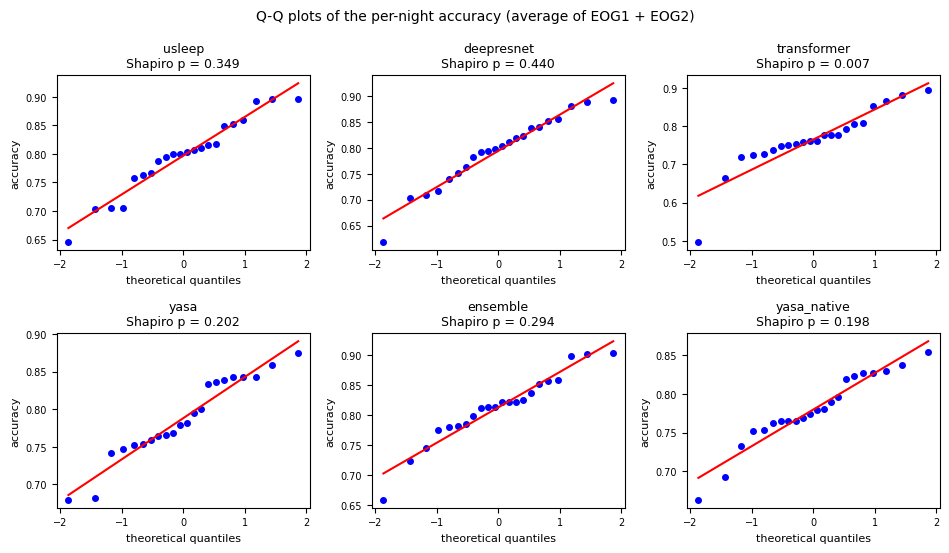

In [15]:
from scipy import stats as sst

# -------------------- CONFIGURE ME --------------------
NORMALITY_METRIC = "accuracy"      # per-night metric to check
NORMALITY_ALPHA  = 0.05            # Shapiro-Wilk: p < this = normality rejected
LOW_POWER_N      = 8               # below this number of nights the test is flagged as low power
# ------------------------------------------------------


def normality_table(df, metric):
    """Shapiro-Wilk per model on the per-night values of `metric` (df has the columns file, model, metric)."""
    rows = []
    for m in dict.fromkeys(df["model"]):
        if m == "manual":
            continue
        x = df.loc[df["model"] == m, metric].dropna().to_numpy(float)
        n = x.size
        row = {"model": m, "n_nights": n, "mean": x.mean() if n else np.nan, "sd": x.std(ddof=1) if n > 1 else np.nan,
               "skewness": sst.skew(x) if n > 2 and np.ptp(x) > 0 else np.nan, "W": np.nan, "p_shapiro": np.nan}
        if n < 3:
            row["result"] = "n < 3: not testable"
        elif np.ptp(x) == 0:
            row["result"] = "all values identical: not testable"
        else:
            W, p = sst.shapiro(x)
            row.update({"W": W, "p_shapiro": p})
            row["result"] = "normality rejected" if p < NORMALITY_ALPHA else "no evidence against normality"
        row["low_power"] = n < LOW_POWER_N
        rows.append(row)
    return pd.DataFrame(rows).set_index("model")


if AVG_TABLES["eval"] is None:
    print("No manual scoring: nothing to test.")
    NORM = None
else:
    NORM = normality_table(AVG_TABLES["eval"], NORMALITY_METRIC)
    print(f"Shapiro-Wilk on the per-night {NORMALITY_METRIC} (average of {' + '.join(EOG_RUNS)}), alpha = {NORMALITY_ALPHA}")
    display(NORM.round(4))
    if NORM["n_nights"].max() < LOW_POWER_N:
        print(f"⚠️ only {int(NORM['n_nights'].max())} night(s): Shapiro-Wilk has little power here. A non-significant result does not show that the data are normal.")
    rej = list(NORM.index[NORM["result"] == "normality rejected"])
    print("normality rejected for: " + (", ".join(rej) if rej else "no model") +
          ("  -> prefer the Wilcoxon result for these models in section 10." if rej else ""))

    ms = list(NORM.index)
    ncol = min(3, len(ms)); nrow = int(np.ceil(len(ms) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.2 * ncol, 2.8 * nrow), squeeze=False)
    for ax in axes.ravel():
        ax.set_visible(False)
    for ax, m in zip(axes.ravel(), ms):
        ax.set_visible(True)
        x = AVG_TABLES["eval"].loc[AVG_TABLES["eval"]["model"] == m, NORMALITY_METRIC].dropna().to_numpy(float)
        if x.size >= 3 and np.ptp(x) > 0:
            sst.probplot(x, dist="norm", plot=ax)
            ax.get_lines()[0].set_markersize(4)
            ax.set_title(f"{m}\nShapiro p = {NORM.loc[m, 'p_shapiro']:.3f}", fontsize=9)
        else:
            ax.text(0.5, 0.5, "not testable", ha="center", va="center", transform=ax.transAxes)
            ax.set_title(m, fontsize=9)
        ax.set_xlabel("theoretical quantiles", fontsize=8); ax.set_ylabel(NORMALITY_METRIC, fontsize=8); ax.tick_params(labelsize=7)
    fig.suptitle(f"Q-Q plots of the per-night {NORMALITY_METRIC} (average of {' + '.join(EOG_RUNS)})", fontsize=10)
    fig.tight_layout()
    fig.savefig(OUT_DIR / f"normality_{NORMALITY_METRIC}_qqplots.png", dpi=200)
    plt.show()
    try:
        NORM.to_excel(OUT_DIR / f"normality_{NORMALITY_METRIC}.xlsx")
    except Exception as e:
        NORM.to_csv(OUT_DIR / f"normality_{NORMALITY_METRIC}.csv")
        print(f"⚠️ Excel export failed ({e}); wrote CSV instead")

## 9. report across files
Averages over all nights (every night counts equally; `±` = standard deviation across nights, `n` = number of nights that enter the average). **All tables use the per-night average of the runs** (`(EOG1 + EOG2) / 2`); 9.0 shows the single runs next to it.
**9.0** runs side by side · **9.1** preprocessing statistics · **9.2** agreement with the manual scoring · **9.3** confusion matrices · **9.4** sleep statistics · **9.5** model agreement · **9.6** figure.
Hypnograms and hypnodensity graphs cannot be averaged and stay per run (`SHOW_PER_FILE = True` or the PNG/CSV files in `OUT_ROOT/<EOG>`).
Everything is also written to `OUT_ROOT/average/report_across_files.xlsx` (mean, sd and per-night values).

Nights in the average of EOG1 + EOG2: 22 | with manual scoring: 22
   ❌ [EOG1] 11_E2_7B_2A_A0_71_Axo_Device_071_20250421_204304_000019.edf: No EEG channel ['FpZ', 'EEG'] found. Available: ['C4', 'EOG']
   ❌ [EOG1] 11_E2_7B_2A_A0_71_Axo_Device_071_20250521_213303_000042.edf: No EEG channel ['FpZ', 'EEG'] found. Available: ['C4', 'EOG']
Recording length: mean 7.52 h (min 3.63, max 9.52)

9.0 The runs side by side (mean ± sd across nights; the report below uses the 'average' column)
   accuracy:


,EOG1,EOG2,average
model,,,
usleep,0.795 ± 0.073,0.798 ± 0.063,0.797 ± 0.066
deepresnet,0.795 ± 0.068,0.794 ± 0.070,0.794 ± 0.068
transformer,0.767 ± 0.085,0.763 ± 0.080,0.765 ± 0.082
yasa,0.784 ± 0.056,0.792 ± 0.054,0.788 ± 0.054
ensemble,0.813 ± 0.061,0.813 ± 0.056,0.813 ± 0.058
yasa_native,0.779 ± 0.048,0.780 ± 0.048,0.780 ± 0.047


   kappa:


,EOG1,EOG2,average
model,,,
usleep,0.698 ± 0.112,0.701 ± 0.104,0.699 ± 0.106
deepresnet,0.698 ± 0.103,0.695 ± 0.110,0.696 ± 0.106
transformer,0.655 ± 0.122,0.646 ± 0.120,0.650 ± 0.120
yasa,0.689 ± 0.084,0.698 ± 0.082,0.694 ± 0.081
ensemble,0.724 ± 0.091,0.720 ± 0.091,0.722 ± 0.091
yasa_native,0.682 ± 0.073,0.683 ± 0.074,0.682 ± 0.072



9.1 Preprocessing statistics (mean ± sd across files; per channel of the prepared EDF)


channel,C4,EOG
duration_h,7.52 ± 1.54,7.52 ± 1.54
n_epochs,901 ± 185,901 ± 185
n_sat_samples,5669 ± 7888,12976 ± 29533
n_interpolated_samples,5669 ± 7888,12976 ± 29533
pct_saturated,0.086 ± 0.110,0.202 ± 0.444
n_sat_segments,13.6 ± 28.3,12.6 ± 18.9
longest_sat_s,16.3 ± 24.8,31.8 ± 64.9
total_sat_s,22.7 ± 31.6,51.9 ± 118
raw_median_uV,1406 ± 13011,2170 ± 10427
raw_IQR_uV,5872 ± 9473,5816 ± 5703


... (16 outputs left out)


9.4 Sleep statistics (minutes unless %; mean ± sd across files; 'manual' only counts files that have a manual scoring)


model,manual,usleep,deepresnet,transformer,yasa,ensemble,yasa_native
TIB,451 ± 92.4,451 ± 92.4,451 ± 92.4,451 ± 92.4,451 ± 92.4,451 ± 92.4,451 ± 92.4
SPT,392 ± 83.7,401 ± 83.4,398 ± 83.1,396 ± 83.3,410 ± 87.6,396 ± 82.9,406 ± 83.9
WASO,52.3 ± 29.4,50.6 ± 32.3,49.4 ± 29.7,49.2 ± 28.6,76.6 ± 38.2,49.6 ± 28.1,66.2 ± 29.6
TST,340 ± 79.5,351 ± 78.6,348 ± 79.1,347 ± 81.3,334 ± 77.9,346 ± 79.7,340 ± 77.1
SE,75.5 ± 9.40,78.0 ± 9.33,77.5 ± 9.45,76.9 ± 9.41,74.1 ± 8.94,76.9 ± 9.38,75.5 ± 8.95
SME,86.5 ± 7.06,87.4 ± 7.15,87.5 ± 6.86,87.3 ± 7.00,81.4 ± 7.79,87.3 ± 6.73,83.7 ± 6.82
SFI,3.44 ± 1.04,3.96 ± 1.26,4.10 ± 1.48,4.21 ± 1.47,6.81 ± 2.97,4.34 ± 1.46,6.07 ± 2.62
SOL,37.3 ± 30.2,33.7 ± 20.3,33.4 ± 18.6,34.2 ± 20.3,33.1 ± 18.2,34.9 ± 20.5,32.4 ± 20.4
SOL_5min,39.2 ± 31.0,39.8 ± 31.5,39.8 ± 31.2,40.4 ± 31.3,40.5 ± 30.8,39.8 ± 31.2,40.2 ± 31.2
Lat_REM,129 ± 35.9,116 ± 37.8,111 ± 39.7,111 ± 39.4,114 ± 33.6,114 ± 37.9,124 ± 35.6



9.5 Agreement between models (mean ± sd across files)


,n files,agreement_%,kappa
pair,,,
usleep vs deepresnet,22,89.6 ± 4.64,0.843 ± 0.076
usleep vs transformer,22,85.1 ± 5.46,0.774 ± 0.087
usleep vs yasa,22,83.0 ± 6.45,0.750 ± 0.098
usleep vs ensemble,22,92.4 ± 3.11,0.884 ± 0.053
usleep vs yasa_native,22,82.2 ± 5.82,0.741 ± 0.088
deepresnet vs transformer,22,86.3 ± 5.34,0.792 ± 0.081
deepresnet vs yasa,22,83.3 ± 6.19,0.757 ± 0.092
deepresnet vs ensemble,22,93.7 ± 2.58,0.904 ± 0.042
deepresnet vs yasa_native,22,83.2 ± 5.64,0.757 ± 0.084


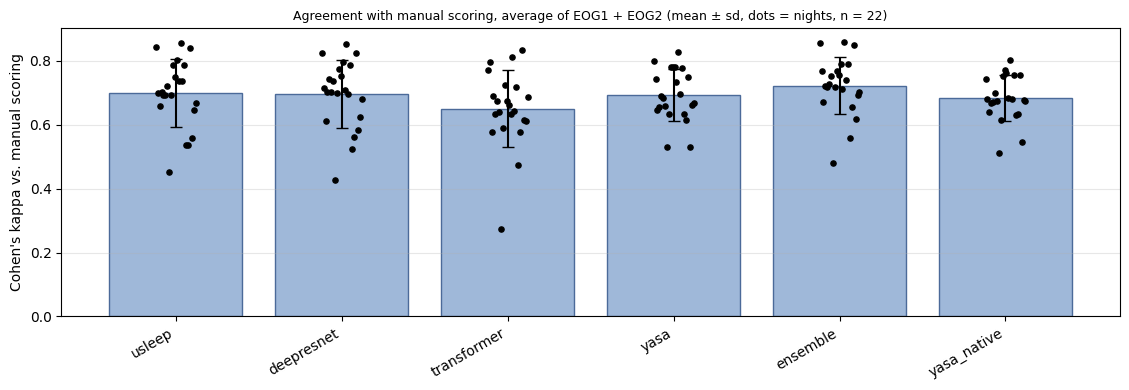


💾 report saved: sleepyland_results_v2/average/report_across_files.xlsx


In [16]:
import warnings


def _fmt(v):
    """Number with a sensible number of decimals (0.059 / 12.3 / 5945)."""
    if pd.isna(v):
        return "–"
    a = abs(v)
    return f"{v:.{0 if a >= 100 else 1 if a >= 10 else 2 if a >= 1 else 3}f}"


def _mean_sd_str(mean, sd):
    """DataFrame of 'mean ± sd' strings (only the mean if there is a single file)."""
    out = mean.astype(object).copy()
    for r_ in mean.index:
        for c_ in mean.columns:
            m, s = mean.loc[r_, c_], sd.loc[r_, c_]
            out.loc[r_, c_] = _fmt(m) if pd.isna(s) else f"{_fmt(m)} ± {_fmt(s)}"
    return out


def _agg(df, by, cols):
    """mean, sd (ddof=1) and n files per group (groups in order of first appearance)."""
    cols = [c_ for c_ in cols if c_ in df.columns]
    g = df.groupby(by, sort=False)
    return g[cols].mean(), g[cols].std(ddof=1), g["file"].nunique().rename("n")


PREP_COLS = ["duration_h", "n_epochs", "n_sat_samples", "n_interpolated_samples", "pct_saturated", "n_sat_segments",
             "longest_sat_s", "total_sat_s", "raw_median_uV", "raw_IQR_uV", "IQR_after_filter_uV", "clip_limit_uV",
             "pct_samples_clipped", "pct_epochs_with_clipping", "pct_epochs_flat", "pct_epochs_artefact"]
EVAL_COLS = ["n_epochs", "accuracy", "kappa", "macro_F1"] + [f"F1_{s}" for s in STAGE_LABELS] + ["%Wake_pred"]


def report_across_files(rep, failed_by_run=None):
    """Section 9 on the per-night averages of the runs (rep = AVG_TABLES)."""
    if rep is None or all(rep.get(k) is None for k in ("eval", "stats", "prep")):
        print("Nothing to report: no night with a result in every run.")
        return None
    sheets = {}                                   # name -> DataFrame, saved to Excel at the end

    def add(name, mean, sd, per_file=None):
        sheets[f"{name}_mean"], sheets[f"{name}_sd"] = mean, sd
        if per_file is not None:
            sheets[f"{name}_per_file"] = per_file

    n_manual = rep["eval"]["file"].nunique() if rep["eval"] is not None else 0
    print(f"Nights in the average of {' + '.join(EOG_RUNS)}: {len(NIGHTS)} | with manual scoring: {n_manual}")
    for run, fd in (failed_by_run or {}).items():
        for f_, e_ in fd.items():
            print(f"   ❌ [{run}] {os.path.basename(f_)}: {e_}")
    if rep["prep"] is not None:
        hrs = rep["prep"].groupby("file")["duration_h"].first()
        print(f"Recording length: mean {hrs.mean():.2f} h (min {hrs.min():.2f}, max {hrs.max():.2f})")

    # ---- 9.0 the single runs next to the average
    if rep["eval"] is not None and rep.get("eval_by_run"):
        print("\n9.0 The runs side by side (mean ± sd across nights; the report below uses the 'average' column)")
        for mt in ("accuracy", "kappa"):
            cols_ = {}
            for lab, df_ in {**rep["eval_by_run"], "average": rep["eval"]}.items():
                mean_, sd_, n_ = _agg(df_, "model", [mt])
                cols_[lab] = _mean_sd_str(mean_, sd_)[mt]
            print(f"   {mt}:"); display(pd.DataFrame(cols_))

    # ---- 9.1 preprocessing
    if rep["prep"] is not None:
        mean, sd, n = _agg(rep["prep"], "channel", PREP_COLS)
        print("\n9.1 Preprocessing statistics (mean ± sd across files; per channel of the prepared EDF)")
        tbl = _mean_sd_str(mean, sd).T
        tbl.loc["n files"] = n.astype(int).astype(str)
        display(tbl)
        print("   pct_epochs_with_clipping = share of 30 s epochs that contain at least one clipped sample; "
              "pct_epochs_flat / pct_epochs_artefact = share of epochs with RMS < 2 µV / > 150 µV after clipping.")
        add("prep", mean, sd, rep["prep"].set_index(["file", "channel"]))

    # ---- 9.2 / 9.3 agreement with manual scoring
    if rep["eval"] is not None:
        mean, sd, n = _agg(rep["eval"], "model", EVAL_COLS)
        wake = rep["manual_wake_pct"]
        print(f"\n9.2 Agreement with manual scoring (mean ± sd across {n_manual} file(s); manual scoring: {np.mean(wake):.0f} % Wake on average)")
        tbl = _mean_sd_str(mean, sd)
        tbl.insert(0, "n files", n.astype(int))
        display(tbl)
        print("   kappa per file:")
        order = list(mean.index)
        piv = rep["eval"].pivot(index="file", columns="model", values="kappa").reindex(columns=order)
        display(piv.round(3))
        add("vs_manual", mean, sd, rep["eval"].set_index(["file", "model"]))

        print(f"\n9.3 Confusion matrices (% of manual epochs, rows = manual; mean over files of the per-file row-normalised matrices)")
        names_r, names_c = [f"manual {s}" for s in STAGE_LABELS], [f"pred {s}" for s in STAGE_LABELS]
        cm_mean = {}
        for m in order:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", category=RuntimeWarning)  # all-NaN rows (stage never scored manually)
                cm_mean[m] = pd.DataFrame(np.nanmean(np.stack(rep["cms"][m]), axis=0), index=names_r, columns=names_c)
            print(f"   {m}  (n = {len(rep['cms'][m])} files)")
            display(cm_mean[m].round(1))
        sheets["confusion_mean_pct"] = pd.concat(cm_mean)

    # ---- 9.4 sleep statistics
    cols = [c_ for c_ in rep["stats"].columns if c_ not in ("model", "file")]
    mean, sd, n = _agg(rep["stats"], "model", cols)
    print("\n9.4 Sleep statistics (minutes unless %; mean ± sd across files; 'manual' only counts files that have a manual scoring)")
    tbl = _mean_sd_str(mean, sd).T
    tbl.loc["n files"] = n.astype(int).astype(str)
    display(tbl)
    add("sleep_stats", mean, sd, rep["stats"].set_index(["file", "model"]))

    # ---- 9.5 model agreement
    if rep["agree"] is not None:
        mean, sd, n = _agg(rep["agree"], "pair", ["agreement_%", "kappa"])
        print("\n9.5 Agreement between models (mean ± sd across files)")
        tbl = _mean_sd_str(mean, sd)
        tbl.insert(0, "n files", n.astype(int))
        display(tbl)
        add("model_agreement", mean, sd, rep["agree"].set_index(["file", "pair"]))

    # ---- 9.6 figure: kappa per model across files
    if rep["eval"] is not None:
        fig, ax = plt.subplots(figsize=(1.4 * len(order) + 3, 4))
        km, ks = rep["eval"].groupby("model", sort=False)["kappa"].mean(), rep["eval"].groupby("model", sort=False)["kappa"].std(ddof=1)
        ax.bar(range(len(order)), km.reindex(order), yerr=ks.reindex(order).fillna(0), capsize=4, color="#9fb8d9", edgecolor="#4b6a99")
        for i, m in enumerate(order):
            v = rep["eval"].loc[rep["eval"]["model"] == m, "kappa"]
            ax.scatter(np.full(len(v), i) + np.linspace(-0.12, 0.12, len(v)), v, color="k", s=14, zorder=3)
        ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=30, ha="right")
        ax.set_ylabel("Cohen's kappa vs. manual scoring"); ax.set_title(f"Agreement with manual scoring, average of {' + '.join(EOG_RUNS)} (mean ± sd, dots = nights, n = {n_manual})", fontsize=9)
        ax.grid(axis="y", alpha=0.3); fig.tight_layout()
        fig.savefig(OUT_DIR / "report_across_files_kappa.png", dpi=200)
        plt.show()

    # ---- save
    xls = OUT_DIR / "report_across_files.xlsx"
    try:
        with pd.ExcelWriter(xls) as xw:
            for name, df in sheets.items():
                df.to_excel(xw, sheet_name=name[:31])
        print(f"\n💾 report saved: {xls}")
    except Exception as e:                        # e.g. openpyxl missing
        folder = OUT_DIR / "report_across_files_csv"
        folder.mkdir(exist_ok=True)
        for name, df in sheets.items():
            df.to_csv(folder / f"{name}.csv")
        print(f"\n⚠️ Excel export failed ({e}); CSV files written to {folder}")
    return rep


report = report_across_files(AVG_TABLES, failed_by_eog)

## 10. non-inferiority tests: one-sided t-test and one-sided Wilcoxon signed-rank test, compared
**Question:** is a model at least as good as human scoring, minus a margin?
**Reference:** the ≈ 0.82 accuracy (κ ≈ 0.76) usually quoted for AASM scoring; **margin** 0.05 absolute points (the nights were scored by one person) → **threshold 0.82 − 0.05 = 0.77**.
**Data:** the per-night `METRIC` (accuracy), **average of the two runs**, one value per night; the night is the unit of analysis.

Both tests are one-sided against the threshold, α = 0.05, no correction between models (the Holm-adjusted p is shown as a sensitivity check only):
* **t-test** (one-sample): H0 mean ≤ threshold, H1 mean > threshold. Assumes approximately normal per-night values (section 8b). Also gives the one-sided 95 % lower confidence bound (non-inferior exactly when it lies above the threshold), Cohen's d and the mean that would have been needed for significance.
* **Wilcoxon signed-rank test** (one-sided, on the differences to the threshold): H0 the differences are symmetric around 0 or negative, H1 the values tend to lie above the threshold. No normality needed, but it uses only the ranks. Reported: R+ (sum of the ranks of the positive differences), the matched-pairs rank-biserial correlation (+1 = all values above the threshold, ranked highest), and the **smallest p-value the test can reach with n nights** (`1 / 2^n` without ties: with 4 nights it is 0.0625 > 0.05, so the test can *never* reject; with 5 nights it is 0.031).

The comparison table puts both side by side. If the two disagree, `note` says why this is likely; where normality was rejected in section 8b, the Wilcoxon result is the one to trust.
*Not rejecting H0 means "non-inferiority not shown", not "model is inferior": with few nights the tests have little power.*

Non-inferiority on the per-night accuracy (average of EOG1 + EOG2, 22 night(s))
H0: accuracy <= 0.770 (= 0.82 - 0.05)  |  H1: accuracy > 0.770  |  one-sided, alpha = 0.05

10.1 One-sided t-test


,n_nights,mean,sd,diff_to_threshold,t,df,p_one_sided,lower_bound,cohens_d,mean_needed,decision,p_holm
model,,,,,,,,,,,,
usleep,22,0.7968,0.0661,0.0268,1.9020,21,0.0355,0.7726,0.4055,0.7943,non-inferior (H0 rejected),0.1775
deepresnet,22,0.7945,0.0683,0.0245,1.6834,21,0.0536,0.7695,0.3589,0.7950,not shown (H0 kept),0.2142
transformer,22,0.7648,0.0818,-0.0052,-0.2971,21,0.6154,0.7348,-0.0634,0.8000,not shown (H0 kept),0.6154
yasa,22,0.7882,0.0537,0.0182,1.5870,21,0.0637,0.7685,0.3383,0.7897,not shown (H0 kept),0.2142
ensemble,22,0.8129,0.0579,0.0429,3.4733,21,0.0011,0.7916,0.7405,0.7912,non-inferior (H0 rejected),0.0068
yasa_native,22,0.7799,0.0467,0.0099,0.9954,21,0.1654,0.7628,0.2122,0.7871,not shown (H0 kept),0.3309


   lower_bound = one-sided 95 % lower confidence bound of the mean; mean_needed = mean at which p would just fall below alpha (given the observed sd).

10.2 One-sided Wilcoxon signed-rank test


,n_nights,median,n_used,R_plus,p_one_sided,rank_biserial,method,min_possible_p,can_reach_alpha,decision,p_holm
model,,,,,,,,,,,
usleep,22,0.8020,22,185.0,0.0293,0.4625,exact,0.0,True,non-inferior (H0 rejected),0.1467
deepresnet,22,0.8008,22,181.0,0.0397,0.4308,exact,0.0,True,non-inferior (H0 rejected),0.1589
transformer,22,0.7615,22,116.0,0.6369,-0.0830,exact,0.0,True,not shown (H0 kept),0.6369
yasa,22,0.7802,22,167.0,0.0991,0.3202,exact,0.0,True,not shown (H0 kept),0.2973
ensemble,22,0.8172,22,219.0,0.0008,0.7312,exact,0.0,True,non-inferior (H0 rejected),0.0050
yasa_native,22,0.7768,22,160.5,0.1348,0.2688,normal approx.,NaN,NaN,not shown (H0 kept),0.2973


   R_plus = sum of the ranks of the positive differences; rank_biserial = (R+ - R-) / (n(n+1)/2); min_possible_p = smallest one-sided p the test can reach with this many nights (no ties); method 'exact' = exact distribution.

10.3 Comparison


,n_nights,mean,median,t,p_ttest,ttest,R_plus,p_wilcoxon,wilcoxon_method,min_possible_p,wilcoxon,shapiro_p,normality,agree
model,,,,,,,,,,,,,,
usleep,22,0.7968,0.8020,1.9020,0.0355,non-inferior,185.0,0.0293,exact,0.0,non-inferior,0.3495,no evidence against normality,True
deepresnet,22,0.7945,0.8008,1.6834,0.0536,not shown,181.0,0.0397,exact,0.0,non-inferior,0.4400,no evidence against normality,False
transformer,22,0.7648,0.7615,-0.2971,0.6154,not shown,116.0,0.6369,exact,0.0,not shown,0.0065,normality rejected,True
yasa,22,0.7882,0.7802,1.5870,0.0637,not shown,167.0,0.0991,exact,0.0,not shown,0.2019,no evidence against normality,True
ensemble,22,0.8129,0.8172,3.4733,0.0011,non-inferior,219.0,0.0008,exact,0.0,non-inferior,0.2938,no evidence against normality,True
yasa_native,22,0.7799,0.7768,0.9954,0.1654,not shown,160.5,0.1348,normal approx.,NaN,not shown,0.1978,no evidence against normality,True


  usleep: t-test non-inferior (p = 0.0355) | Wilcoxon non-inferior (p = 0.0293) -> agree
  deepresnet: t-test not shown (p = 0.0536) | Wilcoxon non-inferior (p = 0.0397) -> DISAGREE  [Wilcoxon significant, t-test not: outliers or a skewed distribution probably inflate the sd of the t-test]
  transformer: t-test not shown (p = 0.6154) | Wilcoxon not shown (p = 0.6369) -> agree  [normality rejected, but both tests give the same decision]
  yasa: t-test not shown (p = 0.0637) | Wilcoxon not shown (p = 0.0991) -> agree
  ensemble: t-test non-inferior (p = 0.0011) | Wilcoxon non-inferior (p = 0.0008) -> agree
  yasa_native: t-test not shown (p = 0.1654) | Wilcoxon not shown (p = 0.1348) -> agree

The two tests give the same decision for 5 of 6 models and differ for 1.


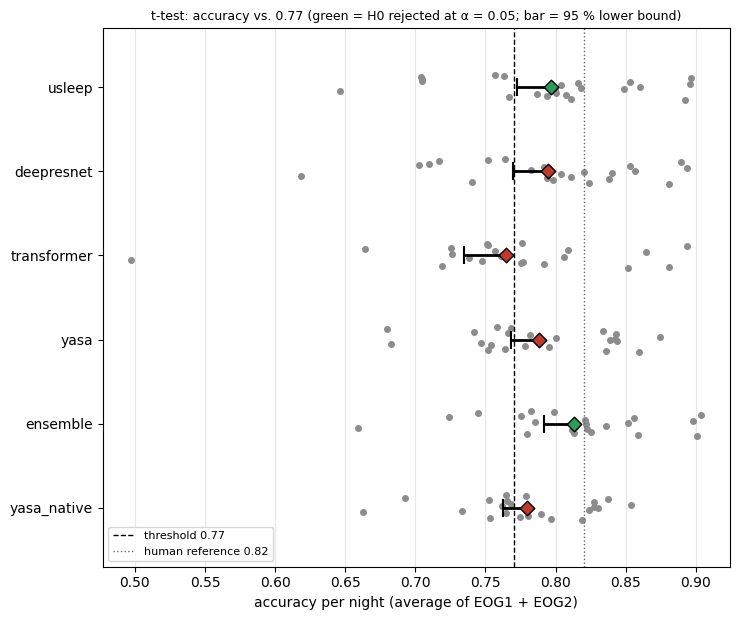

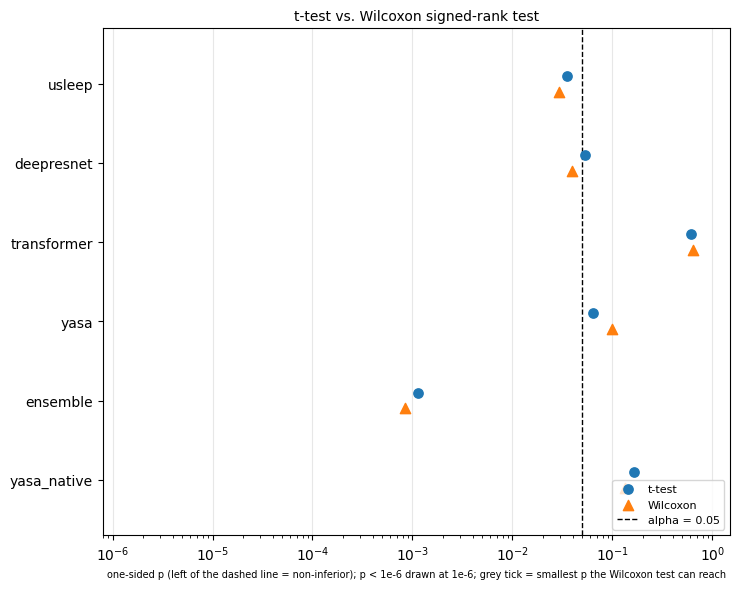


💾 saved: sleepyland_results_v2/average/noninferiority_accuracy.xlsx


In [17]:
# -------------------- CONFIGURE ME --------------------
METRIC      = "accuracy"                          # column of the per-night table: "accuracy", "kappa" or "macro_F1"
REFERENCES  = {"accuracy": 0.82, "kappa": 0.76}   # human-level reference from the literature (AASM inter-scorer agreement)
MARGIN      = 0.05                                # non-inferiority margin in ABSOLUTE points (0.82 - 0.05 = 0.77), not 5 % relative
ALPHA       = 0.05                                # one-sided significance level, both tests
TEST_MODELS = None                                # None = all models; or e.g. ["usleep", "yasa_native", "ensemble"]
# ------------------------------------------------------

if METRIC not in REFERENCES:
    raise KeyError(f"No reference value for METRIC='{METRIC}': add it to REFERENCES (known: {list(REFERENCES)})")
REFERENCE = REFERENCES[METRIC]
THRESHOLD = round(REFERENCE - MARGIN, 10)


def holm_adjust(p):
    """Holm step-down adjusted p-values (NaN are ignored)."""
    p = pd.Series(p, dtype=float)
    out = pd.Series(np.nan, index=p.index)
    valid = p.dropna().sort_values()
    m, running = len(valid), 0.0
    for i, (k, v) in enumerate(valid.items()):
        running = max(running, (m - i) * v)
        out[k] = min(running, 1.0)
    return out


def t_test(x, threshold, alpha):
    """One-sided one-sample t-test, H0: mean <= threshold."""
    n = x.size
    row = {"n_nights": n, "mean": x.mean() if n else np.nan, "sd": np.nan, "diff_to_threshold": np.nan, "t": np.nan, "df": np.nan,
           "p_one_sided": np.nan, "lower_bound": np.nan, "cohens_d": np.nan, "mean_needed": np.nan,
           "non_inferior": False, "decision": "n < 2: no test"}
    if n < 2:
        return row
    mean, sd = x.mean(), x.std(ddof=1)
    se, dof = sd / np.sqrt(n), n - 1
    tcrit = sst.t.ppf(1 - alpha, dof)
    if se == 0:                                       # all nights identical: t undefined
        t = np.inf if mean > threshold else (-np.inf if mean < threshold else 0.0)
        p = 0.0 if mean > threshold else 1.0
    else:
        t = (mean - threshold) / se
        p = float(sst.t.sf(t, dof))                   # one-sided: P(T > t)
    row.update({"sd": sd, "diff_to_threshold": mean - threshold, "t": t, "df": dof, "p_one_sided": p,
                "lower_bound": mean - tcrit * se,                         # one-sided (1-alpha) lower confidence bound
                "cohens_d": (mean - threshold) / sd if sd > 0 else np.nan,
                "mean_needed": threshold + tcrit * se,                    # mean at which p would just be < alpha
                "non_inferior": p < alpha})
    row["decision"] = "non-inferior (H0 rejected)" if p < alpha else "not shown (H0 kept)"
    return row


def wilcoxon_test(x, threshold, alpha):
    """One-sided Wilcoxon signed-rank test on x - threshold, H1: values tend to be above the threshold (zeros are discarded)."""
    d = x - threshold
    row = {"n_nights": x.size, "median": np.median(x) if x.size else np.nan, "n_used": np.nan, "R_plus": np.nan,
           "p_one_sided": np.nan, "rank_biserial": np.nan, "method": "", "min_possible_p": np.nan, "can_reach_alpha": np.nan,
           "non_inferior": False, "decision": "n < 2: no test"}
    nz = d[d != 0]
    row["n_used"] = nz.size
    if nz.size < 2:
        if x.size >= 2:
            row["decision"] = "fewer than 2 non-zero differences: no test"
        return row
    ranks = sst.rankdata(np.abs(nz))                  # average ranks for ties
    r_plus, r_minus = ranks[nz > 0].sum(), ranks[nz < 0].sum()
    ties = np.unique(np.abs(nz)).size < nz.size
    exact = (nz.size <= 50) and not ties and nz.size == d.size       # scipy 'auto': exact distribution only without zeros/ties
    p = float(sst.wilcoxon(d, alternative="greater").pvalue)
    min_p = 0.5 ** nz.size if not ties else np.nan                   # smallest attainable one-sided p (all differences positive)
    row.update({"R_plus": r_plus, "p_one_sided": p, "rank_biserial": (r_plus - r_minus) / (nz.size * (nz.size + 1) / 2),
                "method": "exact" if exact else "normal approx.", "min_possible_p": min_p,
                "can_reach_alpha": (min_p < alpha) if not np.isnan(min_p) else np.nan, "non_inferior": p < alpha})
    if p < alpha:
        row["decision"] = "non-inferior (H0 rejected)"
    elif not np.isnan(min_p) and min_p >= alpha:
        row["decision"] = f"cannot reject with n = {nz.size} (min p = {min_p:.4f})"
    else:
        row["decision"] = "not shown (H0 kept)"
    return row


def run_tests(df, metric, threshold, alpha, models=None):
    """t-test and Wilcoxon per model on the per-night values; returns (t table, Wilcoxon table, comparison table)."""
    rt, rw = [], []
    for m in dict.fromkeys(df["model"]):
        if m == "manual" or (models is not None and m not in models):
            continue
        x = df.loc[df["model"] == m, metric].dropna().to_numpy(float)
        rt.append({"model": m, **t_test(x, threshold, alpha)})
        rw.append({"model": m, **wilcoxon_test(x, threshold, alpha)})
    T, W = pd.DataFrame(rt).set_index("model"), pd.DataFrame(rw).set_index("model")
    T["p_holm"], W["p_holm"] = holm_adjust(T["p_one_sided"]), holm_adjust(W["p_one_sided"])

    nm = normality_table(df, metric)                  # Shapiro-Wilk of exactly these values
    C = pd.DataFrame({"n_nights": T["n_nights"], "mean": T["mean"], "median": W["median"],
                      "t": T["t"], "p_ttest": T["p_one_sided"], "ttest": np.where(T["non_inferior"], "non-inferior", "not shown"),
                      "R_plus": W["R_plus"], "p_wilcoxon": W["p_one_sided"], "wilcoxon_method": W["method"],
                      "min_possible_p": W["min_possible_p"], "wilcoxon": np.where(W["non_inferior"], "non-inferior", "not shown"),
                      "shapiro_p": nm["p_shapiro"].reindex(T.index), "normality": nm["result"].reindex(T.index)})
    C["agree"] = T["non_inferior"] == W["non_inferior"]
    notes = []
    for m in C.index:
        t_ok, w_ok = bool(T.loc[m, "non_inferior"]), bool(W.loc[m, "non_inferior"])
        note = ""
        if T.loc[m, "n_nights"] < 2:
            note = "n < 2: no test"
        elif t_ok != w_ok:
            if t_ok and pd.notna(W.loc[m, "can_reach_alpha"]) and not bool(W.loc[m, "can_reach_alpha"]):
                note = f"Wilcoxon cannot reach alpha with n = {int(W.loc[m, 'n_used'])} nights"
            elif t_ok:
                note = "t-test significant, Wilcoxon not: the t-test result rests on the normality assumption / on the size of the differences, not only on their ranks"
            else:
                note = "Wilcoxon significant, t-test not: outliers or a skewed distribution probably inflate the sd of the t-test"
            if C.loc[m, "normality"] == "normality rejected":
                note += "; normality rejected -> trust Wilcoxon"
        elif C.loc[m, "normality"] == "normality rejected":
            note = "normality rejected, but both tests give the same decision"
        notes.append(note)
    C["note"] = notes
    return T, W, C


def plot_noninferiority(df, T, metric, threshold, reference, path):
    """Dots = nights, diamond = mean, bar = one-sided lower confidence bound of the t-test."""
    ms = list(T.index)
    fig, ax = plt.subplots(figsize=(7.5, 0.75 * len(ms) + 1.8))
    for i, m in enumerate(ms):
        y = len(ms) - 1 - i
        x = df.loc[df["model"] == m, metric].dropna().to_numpy(float)
        ax.scatter(x, y + (np.linspace(-0.15, 0.15, x.size) if x.size > 1 else np.zeros(x.size)), s=16, color="0.55", zorder=2)
        r = T.loc[m]
        if pd.notna(r["lower_bound"]):
            ax.plot([r["lower_bound"], r["mean"]], [y, y], color="k", lw=2, zorder=3)
            ax.scatter(r["lower_bound"], y, marker="|", s=160, color="k", zorder=3)
        ax.scatter(r["mean"], y, marker="D", s=55, zorder=4, edgecolor="k", color="#2a9d5c" if bool(r["non_inferior"]) else "#c0392b")
    ax.axvline(threshold, color="k", ls="--", lw=1, label=f"threshold {threshold:.2f}")
    ax.axvline(reference, color="0.4", ls=":", lw=1, label=f"human reference {reference:.2f}")
    ax.set_yticks(range(len(ms))); ax.set_yticklabels(ms[::-1]); ax.set_ylim(-0.7, len(ms) - 0.3)
    ax.set_xlabel(f"{metric} per night (average of {' + '.join(EOG_RUNS)})"); ax.grid(axis="x", alpha=0.3)
    ax.set_title(f"t-test: {metric} vs. {threshold:.2f} (green = H0 rejected at α = {ALPHA}; bar = 95 % lower bound)", fontsize=9)
    ax.legend(loc="lower left", fontsize=8)
    fig.tight_layout(); fig.savefig(path, dpi=200); plt.show()


def plot_p_comparison(T, W, alpha, path):
    """One-sided p-values of the two tests per model (log axis); the grey tick is the smallest p the Wilcoxon test can reach."""
    ms = list(T.index)
    fig, ax = plt.subplots(figsize=(7.5, 0.7 * len(ms) + 1.8))
    for i, m in enumerate(ms):
        y = len(ms) - 1 - i
        pt, pw, mn = T.loc[m, "p_one_sided"], W.loc[m, "p_one_sided"], W.loc[m, "min_possible_p"]
        if pd.notna(pt): ax.scatter(max(pt, 1e-6), y + 0.1, marker="o", s=45, color="#1f77b4", label="t-test" if i == 0 else None, zorder=3)
        if pd.notna(pw): ax.scatter(max(pw, 1e-6), y - 0.1, marker="^", s=55, color="#ff7f0e", label="Wilcoxon" if i == 0 else None, zorder=3)
        if pd.notna(mn): ax.scatter(mn, y - 0.1, marker="|", s=200, color="0.5", zorder=2)
    ax.axvline(alpha, color="k", ls="--", lw=1, label=f"alpha = {alpha}")
    ax.set_xscale("log"); ax.set_xlim(8e-7, 1.5)
    ax.set_yticks(range(len(ms))); ax.set_yticklabels(ms[::-1]); ax.set_ylim(-0.7, len(ms) - 0.3)
    ax.set_xlabel("one-sided p (left of the dashed line = non-inferior); p < 1e-6 drawn at 1e-6; grey tick = smallest p the Wilcoxon test can reach")
    ax.xaxis.label.set_size(7); ax.grid(axis="x", alpha=0.3); ax.legend(loc="lower right", fontsize=8)
    ax.set_title("t-test vs. Wilcoxon signed-rank test", fontsize=10)
    fig.tight_layout(); fig.savefig(path, dpi=200); plt.show()


if AVG_TABLES["eval"] is None:
    print("No manual scoring: the non-inferiority tests need one.")
    TT = WT = CT = None
else:
    df_ni = AVG_TABLES["eval"][["file", "model", METRIC]].copy()
    TT, WT, CT = run_tests(df_ni, METRIC, THRESHOLD, ALPHA, TEST_MODELS)
    n_nights_ni = int(TT["n_nights"].max())
    print(f"Non-inferiority on the per-night {METRIC} (average of {' + '.join(EOG_RUNS)}, {n_nights_ni} night(s))")
    print(f"H0: {METRIC} <= {THRESHOLD:.3f} (= {REFERENCE:.2f} - {MARGIN:.2f})  |  H1: {METRIC} > {THRESHOLD:.3f}  |  one-sided, alpha = {ALPHA}\n")

    print("10.1 One-sided t-test"); display(TT.drop(columns=["non_inferior"]).round(4))
    print("   lower_bound = one-sided 95 % lower confidence bound of the mean; mean_needed = mean at which p would just fall below alpha (given the observed sd).\n")
    print("10.2 One-sided Wilcoxon signed-rank test"); display(WT.drop(columns=["non_inferior"]).round(4))
    print("   R_plus = sum of the ranks of the positive differences; rank_biserial = (R+ - R-) / (n(n+1)/2); "
          "min_possible_p = smallest one-sided p the test can reach with this many nights (no ties); method 'exact' = exact distribution.\n")
    print("10.3 Comparison"); display(CT.drop(columns=["note"]).round(4))
    for m, r in CT.iterrows():
        d_ = "agree" if r["agree"] else "DISAGREE"
        print(f"  {m}: t-test {r['ttest']} (p = {r['p_ttest']:.4f}) | Wilcoxon {r['wilcoxon']} (p = {r['p_wilcoxon']:.4f}) -> {d_}" + (f"  [{r['note']}]" if r["note"] else ""))
    n_dis = int((~CT["agree"]).sum())
    print(f"\nThe two tests give the same decision for {len(CT) - n_dis} of {len(CT)} models" + ("." if not n_dis else f" and differ for {n_dis}."))
    if n_nights_ni < 5:
        print(f"⚠️ With {n_nights_ni} night(s) the Wilcoxon test cannot reach p < {ALPHA} at all (smallest possible p = {0.5 ** n_nights_ni:.4f}); "
              f"it can only be used from 5 nights on.")
    elif n_nights_ni < 8:
        print(f"⚠️ Only {n_nights_ni} nights: low power for both tests, and the normality assumption of the t-test cannot be checked reliably.")

    plot_noninferiority(df_ni, TT, METRIC, THRESHOLD, REFERENCE, OUT_DIR / f"noninferiority_{METRIC}_ttest.png")
    plot_p_comparison(TT, WT, ALPHA, OUT_DIR / f"noninferiority_{METRIC}_p_comparison.png")

    xls = OUT_DIR / f"noninferiority_{METRIC}.xlsx"
    settings = pd.DataFrame({"setting": ["metric", "reference", "margin", "threshold", "alpha (one-sided)", "runs averaged", "nights"],
                             "value": [METRIC, REFERENCE, MARGIN, THRESHOLD, ALPHA, " + ".join(EOG_RUNS), ", ".join(NIGHTS)]})
    try:
        with pd.ExcelWriter(xls) as xw:
            CT.to_excel(xw, sheet_name="comparison")
            TT.to_excel(xw, sheet_name="ttest")
            WT.to_excel(xw, sheet_name="wilcoxon")
            df_ni.pivot(index="file", columns="model", values=METRIC).to_excel(xw, sheet_name="per_night")
            if NORM is not None:
                NORM.to_excel(xw, sheet_name="normality")
            settings.to_excel(xw, sheet_name="settings", index=False)
        print(f"\n💾 saved: {xls}")
    except Exception as e:
        folder = OUT_DIR / f"noninferiority_{METRIC}_csv"
        folder.mkdir(exist_ok=True)
        for name, d_ in {"comparison": CT, "ttest": TT, "wilcoxon": WT}.items():
            d_.to_csv(folder / f"{name}.csv")
        print(f"\n⚠️ Excel export failed ({e}); wrote CSV files to {folder}")